In [ ]:
!pip install pmdarima -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 9.2 MB/s eta 0:00:00


In [ ]:
import warnings
import os
import numpy as np
import pandas as pd

import kagglehub
from kagglehub import KaggleDatasetAdapter

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter

from scipy import stats

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf, pacf

from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

import pmdarima as pm

#Série: Hourly Energy Consumption

Dataset: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption

## Carregamento dos dados

In [ ]:
# Carregamento do dataset
# Como o dataset tem informações de várias distribuidoras, a PJME foi aleatoriamente escolhida
file_path = 'PJME_hourly.csv'
data = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "robikscube/hourly-energy-consumption",
  file_path,
  )

Using Colab cache for faster access to the 'hourly-energy-consumption' dataset.


In [ ]:
# Conversão da coluna de tempo
data['Datetime'] = pd.to_datetime(data['Datetime'])

# Há algumas duplicatas e valores faltantes que são corrigidos aqui
data = (data.groupby("Datetime")["PJME_MW"].mean()
           .sort_index()
           .asfreq("h")
           .interpolate())

In [ ]:
# Amostragem dos dados para melhorar a visualização
df = data.loc["2009-05-01":"2009-08-01"]

print(len(df))
print(df.index.to_series().diff().value_counts())

2232
Datetime
0 days 01:00:00    2231
Name: count, dtype: int64


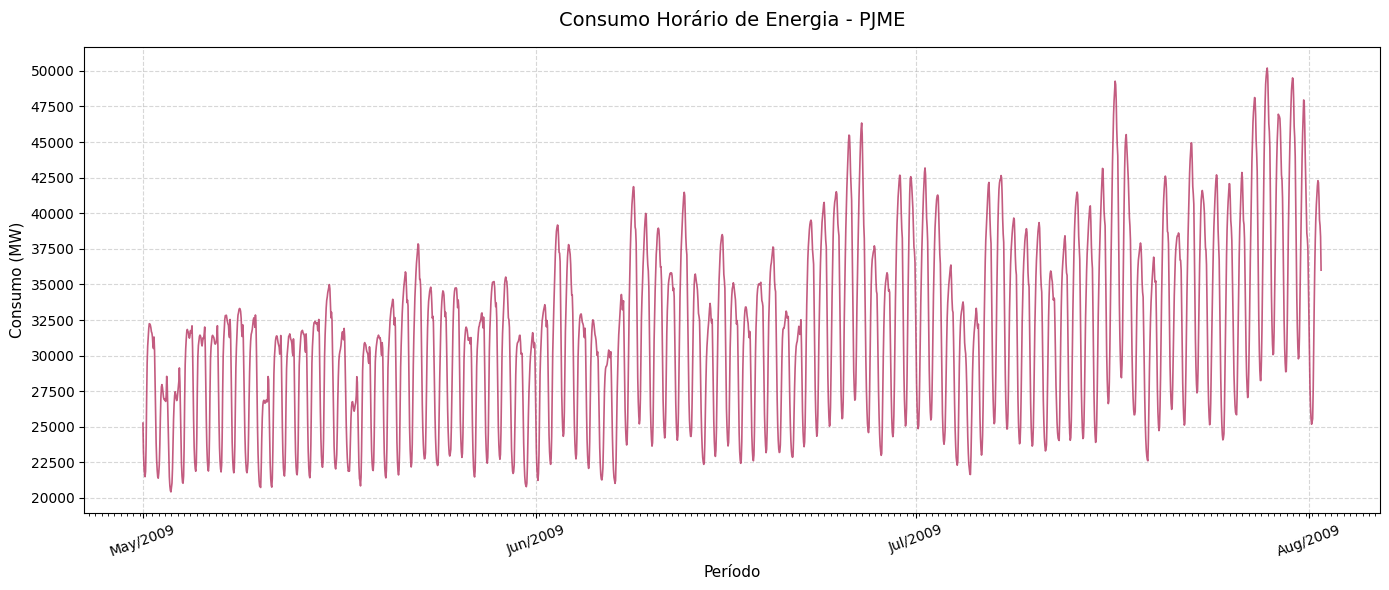

In [ ]:
# Plot dos dados em gráfico
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df, color='#b53360', linewidth=1.2, alpha=0.8)

# Marcador temporal  -  Eixo X
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 18]))

# Consumo de MW em intervalos de 2,5k - Eixo Y
ax.yaxis.set_major_locator(ticker.MultipleLocator(2500))

ax.set_title("Consumo Horário de Energia - PJME", fontsize=14, pad=15)
ax.set_xlabel("Período", fontsize=11)
ax.set_ylabel("Consumo (MW)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.xticks(rotation=20, ha='center')
plt.tight_layout()

plt.show()

A série tem duas componentes visíveis: uma tendência crescente (consumo MW) e um ciclo diário.

## Análise dos dados

### Características estatísticas (série completa)

In [ ]:
# estatísticas descritivas
print(df.describe().round(2))
print("Variância:", round(df.var(), 2))

# tendência: inclinação da reta ajustada
anos = np.arange(len(df)) / 12
print("Inclinação da tendência linear:", round(np.polyfit(anos, df.values, 1)[0], 2))

# estacionariedade (ADF: H0 = não estacionária | KPSS: H0 = estacionária)
def testar_estacionariedade(x, nome):
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    print(f"{nome:<34} ADF p = {p_adf:.4f} ({'estacionária' if p_adf < 0.05 else 'NÃO estacionária'}) | "
          f"KPSS p = {p_kpss:.3f} ({'estacionária' if p_kpss >= 0.05 else 'NÃO estacionária'})")

testar_estacionariedade(df, "Série original")

count     2232.00
mean     31578.69
std       6220.96
min      20427.00
25%      26560.75
50%      31364.00
75%      35634.75
max      50201.00
Name: PJME_MW, dtype: float64
Variância: 38700296.94
Inclinação da tendência linear: 52.68
Série original                     ADF p = 0.0013 (estacionária) | KPSS p = 0.010 (NÃO estacionária)


### Decomposição (STL): tendência, sazonalidade e resíduo

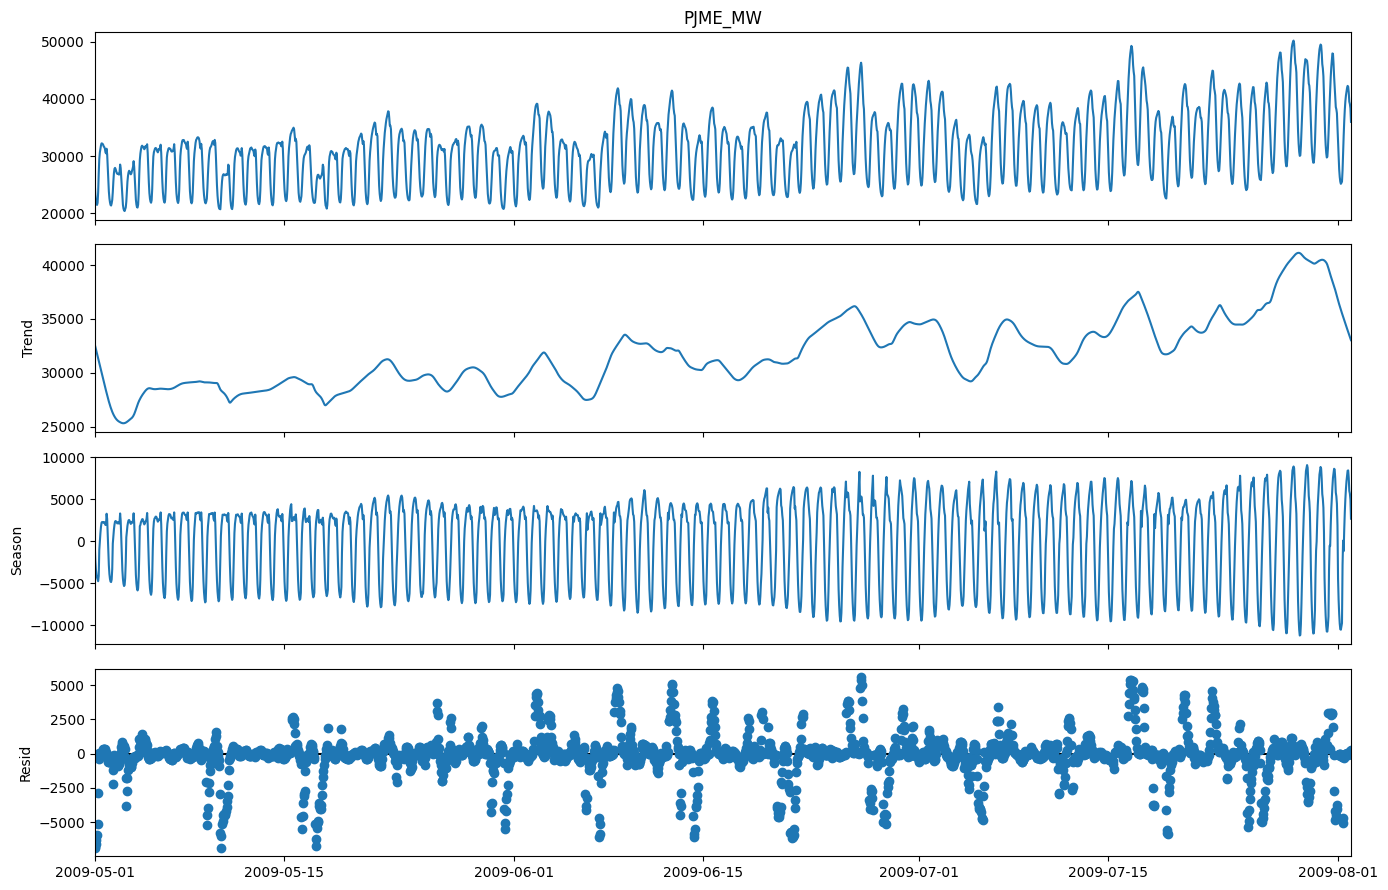

Força da sazonalidade: 0.906 | Força da tendência: 0.827
Pico sazonal às 17h (+5142 MW) | vale às 4h (-8009 MW)


In [ ]:
serie = df.squeeze()                  # Series em MW
serie = serie.asfreq("h")             # Frequência horária

stl = STL(serie, period=24, robust=True).fit()   # period=24: ciclo diário
fig = stl.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

# força da sazonalidade e da tendência (0 = inexistente, 1 = domina a série)
forca_sazonal = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
forca_tendencia = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
print(f"Força da sazonalidade: {forca_sazonal:.3f} | Força da tendência: {forca_tendencia:.3f}")

# perfil sazonal médio: efeito de cada hora do dia, em MW
perfil = stl.seasonal.groupby(stl.seasonal.index.hour).mean()
print(f"Pico sazonal às {perfil.idxmax()}h ({perfil.max():+.0f} MW) | "
      f"vale às {perfil.idxmin()}h ({perfil.min():+.0f} MW)")

### Correlogramas (ACF e PACF)

A identificação da ordem do modelo usa apenas o trecho de treino.

In [ ]:
def plot_acf_pacf(x, lags, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    plot_acf(x, lags=lags, ax=axes[0])
    plot_pacf(x, lags=lags, ax=axes[1], method='ywm')
    axes[0].set_title(f'Autocorrelação (ACF) - {titulo}')
    axes[1].set_title(f'Autocorrelação Parcial (PACF) - {titulo}')
    for ax in axes:
        ax.set_xlabel('Lags (horas de defasagem)')
        ax.set_ylabel('Autocorrelação')
        ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
df_train = df.iloc[:1606] # Subconjunto de treinamento, 75% dos dados iniciais

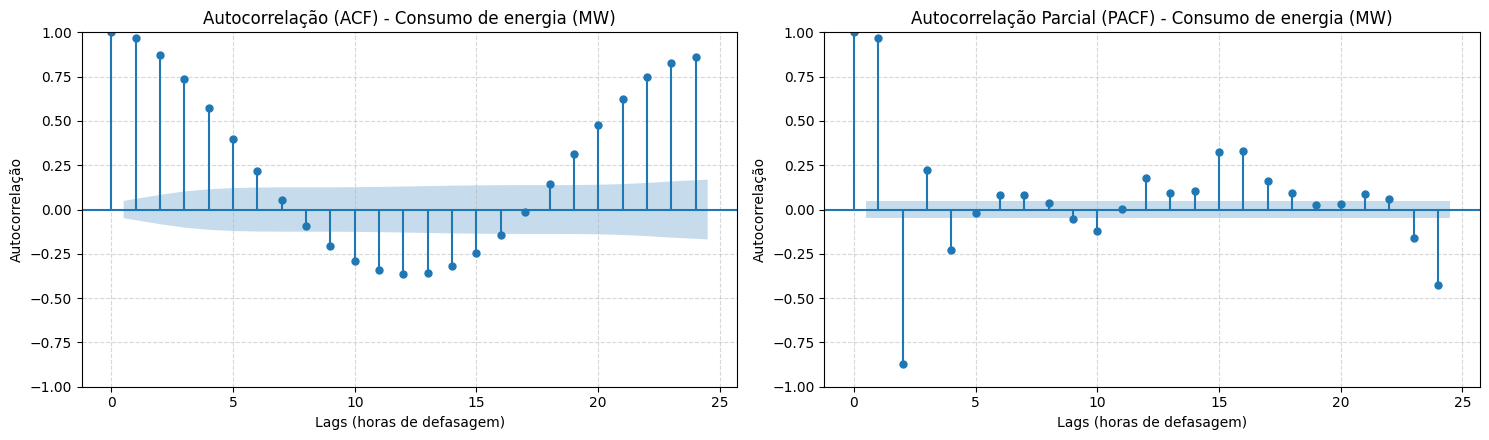

In [ ]:
# 24 lags: ciclo diário
plot_acf_pacf(df_train, 24, "Consumo de energia (MW)")

A ACF revela sazonalidade, com pico nas extremidades, próximo a meia-noite (24h), e um mínimo local próximo de meio-dia (12h), com leve decaimento e crescimento entre os valores extremos. Por sua vez, a PACF tem comportamento instável, com muitos pontos diversos signoficativos (fora do intervalo


### Remoção de sazonalidade

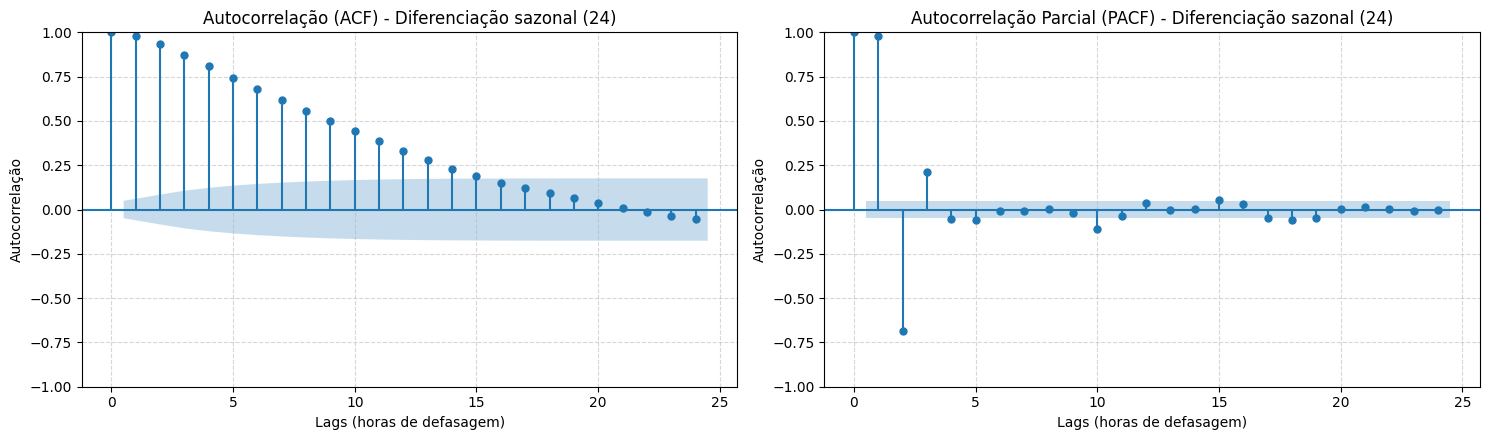

In [ ]:
noseason_df = df_train.diff(24).dropna()
# Como os dados são diários, o diff corresponde a um dia 24h

plot_acf_pacf(noseason_df, 24, "Diferenciação sazonal (24)")

A diferença sazonal remove o ciclo diário, mas a ACF ainda decai devagar: sobrou a tendência.

### Remoção de tendência

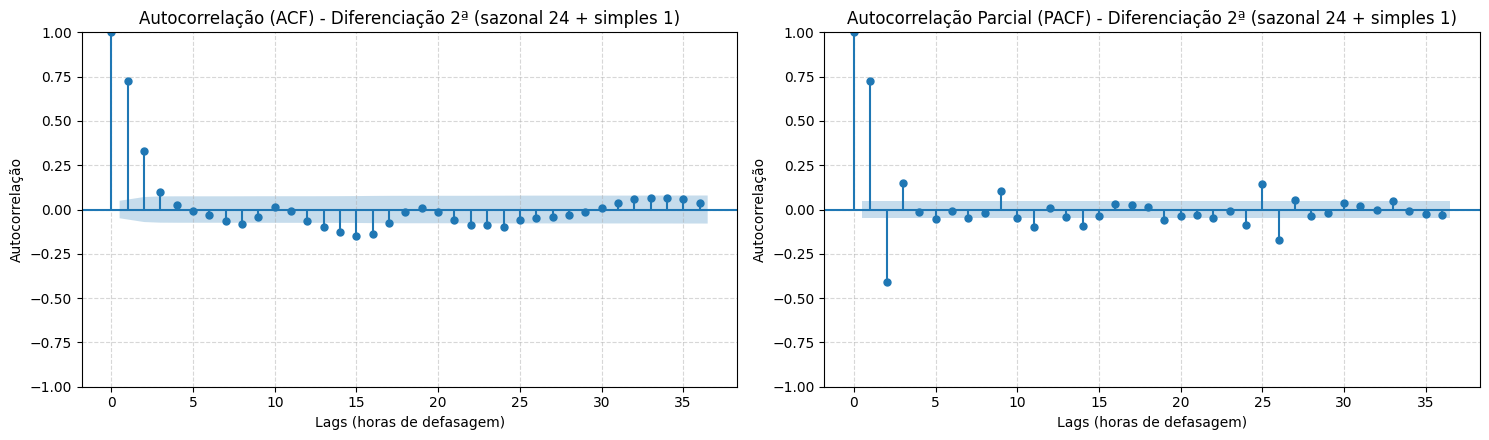

In [ ]:
# Aplicação da diferenciação em 1
notendency_df = noseason_df.diff(1).dropna()

plot_acf_pacf(notendency_df, 36, "Diferenciação 2ª (sazonal 24 + simples 1)")

Depois das duas diferenciações, a ACF decai exponencialmente, mas ainda apresenta lags significativos próximos de 15, indicando que ainda há algum padrão que não foi removido com as operações. Por sua vez, a PACF corta logo nos lags iniciais (3) e apresenta alguns lags sinigificativos pŕoximos de 25.

### Verificação de resíduo

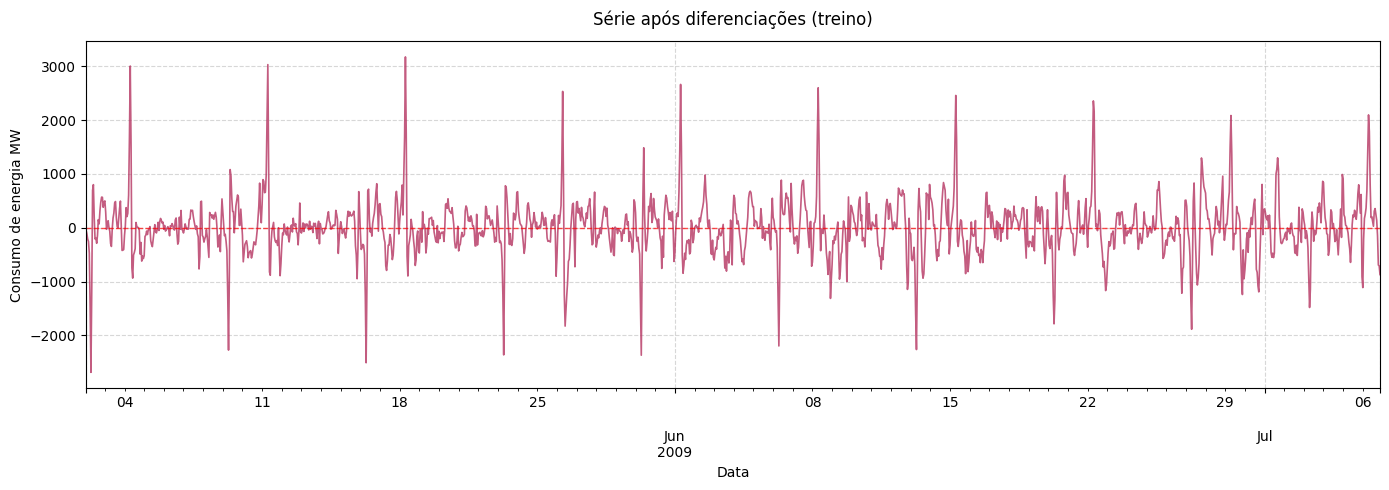

Após diferenciação sazonal (24)    ADF p = 0.0000 (estacionária) | KPSS p = 0.100 (estacionária)
Após sazonal (24) + simples (1)    ADF p = 0.0000 (estacionária) | KPSS p = 0.100 (estacionária)


In [ ]:
# plotagem do que sobrou da série
fig, ax = plt.subplots(figsize=(14, 5))
notendency_df.plot(ax=ax, color=COR, linewidth=1.2, alpha=0.8)

plt.title('Série após diferenciações (treino)', fontsize=12, pad=12)
plt.xlabel('Data')
plt.ylabel('Consumo de energia MW')

plt.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

testar_estacionariedade(noseason_df, "Após diferenciação sazonal (24)")
testar_estacionariedade(notendency_df, "Após sazonal (24) + simples (1)")

A série diferenciada oscila em torno de zero com variância estável e passa nos testes de estacionariedade.

Conclusão da identificação: p = 3, d = 1, q = 0.

## Pré-processamento


### Normalização e Hold-out

Log será aplicado, assim como diferenciação por 24.

In [ ]:
# Log para normalização
df_log = np.log1p(df)

# Diferenciação por 24
df_diff = df_log.diff(24).dropna()

# Hold-out 50%, 25%, 25%
n = len(df_diff)
a = int(n * 0.5)
b = int(n * 0.75)

# Eram 2.232 instâncias, após diferenciação por 24 temos: 2.208
df_train = df_diff.iloc[:a]      # 1.104 instâncias
df_val = df_diff.iloc[a:b]       # 552 instâncias
df_test = df_diff.iloc[b:]       # 552 instâncias

df_train_est = df_diff.iloc[:b]  # 75%

Total: 2208 | treino: 1104 | validação: 552 | teste: 552
Treino     05/2009 → 06/2009  (1104 horas)
Validação  06/2009 → 07/2009  (552 horas)
Teste      07/2009 → 08/2009  (552 horas)


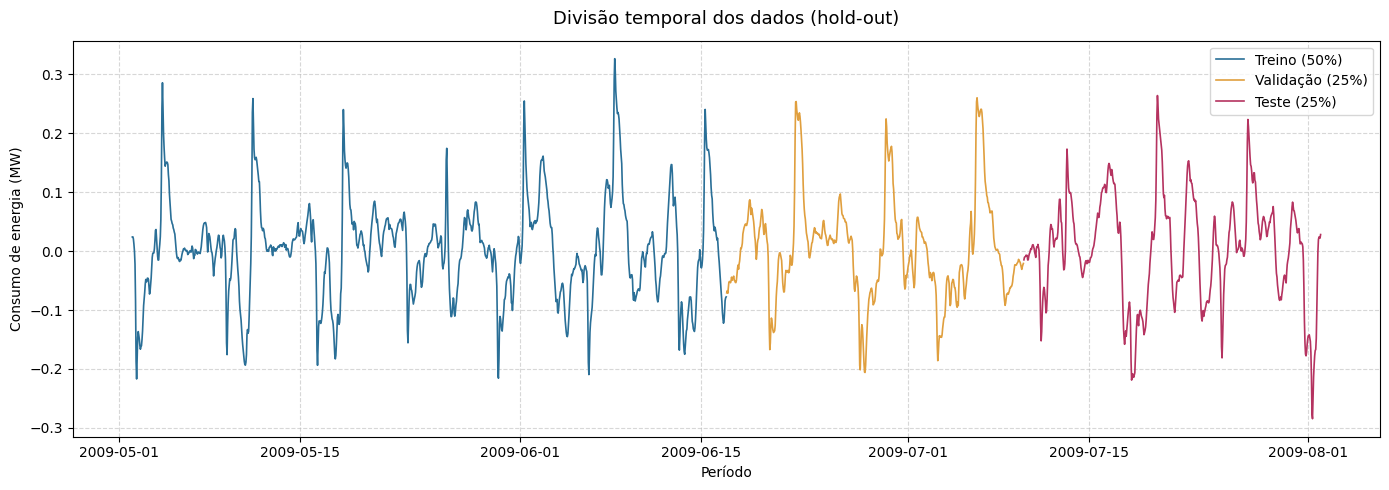

In [ ]:
print(f"Total: {n} | treino: {len(df_train)} | validação: {len(df_val)} | teste: {len(df_test)}")
for nome, parte in [("Treino", df_train), ("Validação", df_val), ("Teste", df_test)]:
    print(f"{nome:<10} {parte.index.min().strftime('%m/%Y')} → {parte.index.max().strftime('%m/%Y')}  ({len(parte)} horas)")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train, color='#2a6f97', linewidth=1.2, label='Treino (50%)')
ax.plot(df_val.index, df_val, color='#e09f3e', linewidth=1.2, label='Validação (25%)')
ax.plot(df_test.index, df_test, color=COR, linewidth=1.2, label='Teste (25%)')
ax.set_title('Divisão temporal dos dados (hold-out)', fontsize=13, pad=12)
ax.set_xlabel('Período')
ax.set_ylabel('Consumo de energia (MW)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

###Função auxiliar

In [ ]:
RESULTADOS = {}

def registrar(nome, prevs_ppm, config):
    prevs_ppm = np.asarray(prevs_ppm)
    tabela = pd.DataFrame([metricas(real_teste, p) for p in prevs_ppm])
    RESULTADOS[nome] = {'prev': prevs_ppm, 'metricas': tabela, 'config': config}
    print(f"{nome}: RMSE teste = {tabela['RMSE (ppm)'].mean():.4f} ppm (± {tabela['RMSE (ppm)'].std():.4f})")

## Parte I: Modelos estatísticos


### Metodologia de Box & Jenkins

In [ ]:
'''
Parâmetros do ARIMA:
Pela análise dos gráficos gerados
p = 1, 2, 3     # ACF decresce lentamente e PACF quebra   (autorregressiva)
d = 1           # 1 conforme os gráficos                  (diferenciação)
q = 1, 2, 3                                               (média móvel)
'''

# Combinações testadas
testes = [(1,1,1),(1,1,2),(1,1,3),
          (2,1,1),(2,1,2),(2,1,3),
          (3,1,1),(3,1,2),(3,1,3)]

for ordem in testes:
    m = ARIMA(df_train_est, order=ordem).fit()
    print(ordem, "AIC:", round(m.aic, 1), "BIC:", round(m.bic, 1),
          "| Ljung-Box lag 1 p =",
          round(acorr_ljungbox(m.resid.iloc[25:], lags=[1])["lb_pvalue"].iloc[0], 4))

(1, 1, 1) AIC: -10128.2 BIC: -10111.9 | Ljung-Box lag 1 p = 0.0917
(1, 1, 2) AIC: -10181.1 BIC: -10159.5 | Ljung-Box lag 1 p = 0.8043
(1, 1, 3) AIC: -10197.5 BIC: -10170.4 | Ljung-Box lag 1 p = 0.852
(2, 1, 1) AIC: -10182.5 BIC: -10160.9 | Ljung-Box lag 1 p = 0.7635
(2, 1, 2) AIC: -10189.2 BIC: -10162.2 | Ljung-Box lag 1 p = 0.9416
(2, 1, 3) AIC: -10188.5 BIC: -10156.0 | Ljung-Box lag 1 p = 0.9556
(3, 1, 1) AIC: -10185.0 BIC: -10157.9 | Ljung-Box lag 1 p = 0.8406
(3, 1, 2) AIC: -10187.8 BIC: -10155.3 | Ljung-Box lag 1 p = 0.8217
(3, 1, 3) AIC: -10189.7 BIC: -10151.9 | Ljung-Box lag 1 p = 0.8624


O candidato com melhor desempenho geral (menores AIC e BIC, e significativo Ljung-Box lag 1 p) tem parâmetros (1, 1, 3): p = 1, d = 1, q = 3.

### Auto-ARIMA

In [ ]:
!pip install pmdarima
import pmdarima as pm

In [ ]:
# Aplicação do auto-ARIMA
auto = pm.auto_arima(
    df_train_est,
    d=1,                              # d = 1, fixo
    start_p=0, max_p=4,
    start_q=0, max_q=4,
    seasonal=False,                   # sem parte sazonal, ARIMA apenas
    information_criterion="bic",      # BIC como métrica
    stepwise=True,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
)

print(auto.order)
print(auto.summary())

Performing stepwise search to minimize bic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : BIC=-8664.013, Time=0.73 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : BIC=-9748.707, Time=1.31 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : BIC=-9820.754, Time=3.92 sec
 ARIMA(0,1,0)(0,0,0)[0]             : BIC=-8671.420, Time=0.40 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : BIC=-10104.538, Time=4.79 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : BIC=-10153.459, Time=1.15 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : BIC=-10127.827, Time=1.83 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : BIC=-10150.472, Time=11.29 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : BIC=-10154.851, Time=4.27 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : BIC=-10156.206, Time=7.02 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : BIC=-10142.445, Time=4.35 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : BIC=-10162.466, Time=10.82 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : BIC=-10162.089, Time=4.12 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : BIC=-10148.630, Time=0.85 sec
 ARIMA(

###Avaliação ARIMA
Como o modelo encontrado pela métodologia de Box & Jenkins é o mesmo encontrado pelo auto-ARIMA, a avaliação será uma só.

In [ ]:
# Resultados do melhor modelo testado
# Critério: menores AIC e BIC
modelo_arima = ARIMA(df_train_est, order=(1, 1, 3)).fit()
print(modelo_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                PJME_MW   No. Observations:                 1656
Model:                 ARIMA(1, 1, 3)   Log Likelihood                5103.728
Date:                Tue, 06 Oct 2026   AIC                         -10197.455
Time:                        22:06:27   BIC                         -10170.397
Sample:                    05-02-2009   HQIC                        -10187.425
                         - 07-09-2009                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5471      0.095     -5.736      0.000      -0.734      -0.360
ma.L1          1.6346      0.097     16.876      0.000       1.445       1.824
ma.L2          1.1554      0.102     11.326      0.0

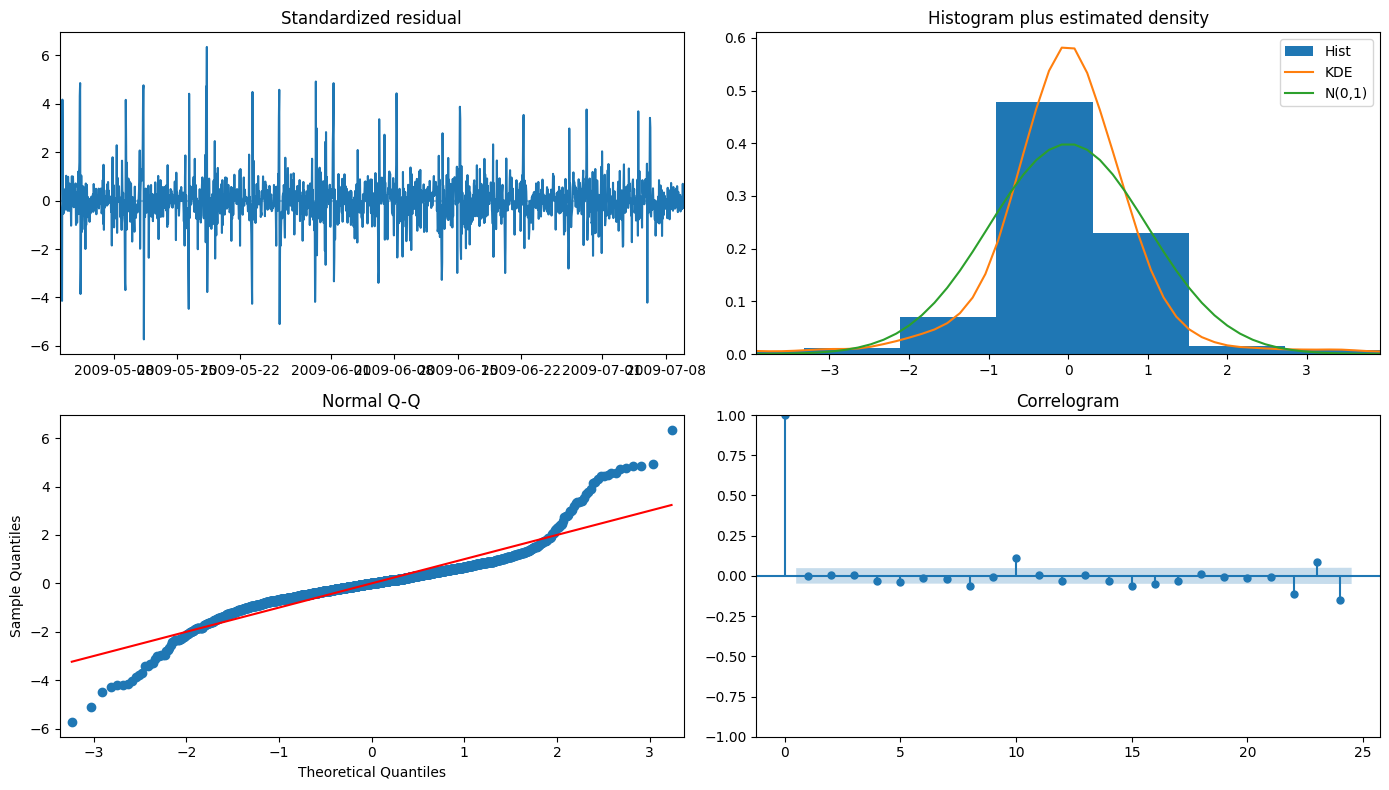

In [ ]:
auto.plot_diagnostics(figsize=(14, 8), lags=24)
plt.tight_layout()
plt.show()

In [ ]:
def metricas(real, pred):
  erro = real - pred
  rmse = np.sqrt((erro**2).mean())
  mae  = erro.abs().mean()
  mape = (erro.abs() / real).mean() * 100

  print(f"RMSE: {rmse:.1f} MW")
  print(f"MAE : {mae:.1f} MW")
  print(f"MAPE: {mape:.2f} %")

def salva_metrica(real, pred):
  erro = real - pred
  return {"RMSE": np.sqrt((erro**2).mean()),
          "MAE": erro.abs().mean(),
          "MAPE%": (erro.abs() / real).mean() * 100}

In [ ]:
# Previsão
res = modelo_arima
previsoes = []
for t in df_test.index:
  previsoes.append(res.forecast(1).iloc[0])         # Prevê 1 passo
  res = res.append(df_diff.loc[[t]], refit=False)   # Adiciona o valor real para prever o próximo

pred_w = pd.Series(previsoes, index=df_test.index)

# Reverte a diferença de 24: soma o log real de 24 h antes
y_prev_log = pred_w + df_log.squeeze().shift(24).loc[df_test.index]

# Reverte o log, volta para MW
y_prev = np.exp(y_prev_log)

In [ ]:
# Métricas
y_real = df.squeeze().loc[df_test.index]      # Consumo real
y_prev = y_prev.squeeze()

metricas(y_real, y_prev)

RMSE: 318.2 MW
MAE : 233.9 MW
MAPE: 0.68 %


## Parte II: Aprendizado de Máquina

In [ ]:
import copy
import itertools

In [ ]:
# Janelas
w_all = df_diff.squeeze()                  # série contínua: treino + validação + teste
_cache = {}

def prepara(L):
  if L not in _cache:
    v = w_all.values
    X = np.stack([v[t - L:t] for t in range(L, len(v))])
    y = v[L:]
    datas = w_all.index[L:]                 # data do alvo de cada janela
    _cache[L] = (X, y,
                  datas.isin(df_train.index),
                  datas.isin(df_val.index),
                  datas.isin(df_test.index),
                  datas)
  return _cache[L]

### MLP (Multilayer Perceptron)

In [ ]:
# Treinamento
def treina(L, h, alpha, lr, seed, max_ep=500, paciencia=10):
    X, y, tr, va, te, datas = prepara(L)
    mlp = MLPRegressor(hidden_layer_sizes=h, alpha=alpha,
                       learning_rate_init=lr, batch_size=32,
                       random_state=seed)
    melhor, melhor_mlp, sem = np.inf, None, 0
    for _ in range(max_ep):
        mlp.partial_fit(X[tr], y[tr])
        erro = np.mean((y[va] - mlp.predict(X[va])) ** 2)
        if erro < melhor:
            melhor, melhor_mlp, sem = erro, copy.deepcopy(mlp), 0
        else:
            sem += 1
            if sem >= paciencia:
                break
    return melhor_mlp, melhor

In [ ]:
# Grid-Search na validação
grade = {
    "L":     [12, 24, 48],
    "h":     [(16,), (32,), (32,16)],         # arquitetura
    "alpha": [1e-5, 1e-3],                     # regularização L2
    "lr":    [1e-3, 1e-2],                     # taxa de aprendizado
}
SEEDS_GRID = (0, 1)                            # sementes usadas só na busca / validação

linhas = []
for L, h, alpha, lr in itertools.product(*grade.values()):
    erros = [treina(L, h, alpha, lr, s)[1] for s in SEEDS_GRID]
    linhas.append({"L": L, "h": h, "alpha": alpha, "lr": lr,
                   "MSE val": np.mean(erros)})

busca = pd.DataFrame(linhas).sort_values("MSE val").reset_index(drop=True)

In [ ]:
# Top resultados
print(busca.head(5))

best_mlp = busca.iloc[0]
L, h, alpha, lr = int(best_mlp["L"]), best_mlp["h"], best_mlp["alpha"], best_mlp["lr"]
print("\nMelhor configuração:", L, h, alpha, lr)

    L      h    alpha     lr   MSE val
0  12  (16,)  0.00001  0.001  0.000085
1  12  (32,)  0.00001  0.001  0.000088
2  12  (32,)  0.00100  0.001  0.000091
3  24  (32,)  0.00100  0.001  0.000094
4  24  (16,)  0.00001  0.001  0.000096

Melhor configuração: 12 (16,) 1e-05 0.001


In [ ]:
# Treinamento e resultado do melhor modelo encontrado
X, y, tr, va, te, datas = prepara(L)
idx_te = datas[te]
log_full = df_log.squeeze()
y_real = df.squeeze().loc[idx_te]

resultados_mlp = []
preds_mlp = []

for seed in range(10):
  mlp, _ = treina(L, h, alpha, lr, seed)
  pred_w = pd.Series(mlp.predict(X[te]), index=idx_te)       # 1 passo à frente
  y_prev = np.exp(pred_w + log_full.shift(24).loc[idx_te])   # reverte as transformações (diff e log)
  resultados_mlp.append(salva_metrica(y_real, y_prev))

  preds_mlp.append(np.exp(pred_w + log_full.shift(24).loc[idx_te]))   # em MW

preds_mlp = pd.concat(preds_mlp, axis=1)     # 1 coluna por semente
preds_mlp.columns = [f"seed_{s}" for s in range(10)]

resultados_mlp = pd.DataFrame(resultados_mlp)

In [ ]:
# Conclusão dos resultados
print("\nMLP (melhor modelo) - média e desvio padrão em 10 sementes:")
print(resultados_mlp.agg(["mean", "std"]).T.round(2))


MLP (melhor modelo) - média e desvio padrão em 10 sementes:
         mean    std
RMSE   356.27  40.05
MAE    255.01  21.72
MAPE%    0.74   0.06


### SVR (Support Vector Regression)

In [ ]:
# Grid-Search
grade_svr = {
    "L":       [12, 24, 48],               # horas passadas na entrada
    "C":       [1, 10, 100],               # penalidade dos erros
    "epsilon": [1e-4, 1e-3, 1e-2],         # largura da faixa sem penalidade
    "gamma":   ["scale", "auto"],          # alcance do kernel RBF
}

linhas = []
for L, C, eps, gamma in itertools.product(*grade_svr.values()):
    X, y, tr, va, te, datas = prepara(L)
    svr = SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma)
    svr.fit(X[tr], y[tr])
    mse = np.mean((y[va] - svr.predict(X[va])) ** 2)
    linhas.append({"L": L, "C": C, "epsilon": eps, "gamma": gamma, "MSE val": mse})

busca_svr = pd.DataFrame(linhas).sort_values("MSE val").reset_index(drop=True)

In [ ]:
# Top resultados SVR
print(busca_svr.head(5))

best_svr = busca_svr.iloc[0]
L, C, eps, gamma = int(best_svr["L"]), best_svr["C"], best_svr["epsilon"], best_svr["gamma"]
print("\nMelhor configuração:", L, C, eps, gamma)

    L    C  epsilon gamma   MSE val
0  48  100   0.0010  auto  0.000082
1  48  100   0.0001  auto  0.000083
2  12  100   0.0001  auto  0.000083
3  12  100   0.0010  auto  0.000084
4  24  100   0.0001  auto  0.000085

Melhor configuração: 48 100 0.001 auto


In [ ]:
# Melhor modelo SVR
X, y, tr, va, te, datas = prepara(L)
idx_te = datas[te]

svr = SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma).fit(X[tr], y[tr])
pred_w = pd.Series(svr.predict(X[te]), index=idx_te)

y_prev_svr = np.exp(pred_w + df_log.squeeze().shift(24).loc[idx_te])   # volta a MW
y_real = df.squeeze().loc[idx_te]

print("\nSVR (melhor modelo):")
print(pd.Series(metricas(y_real, y_prev_svr)).round(2))


SVR (melhor modelo):
RMSE: 328.2 MW
MAE : 234.9 MW
MAPE: 0.68 %
Series([], dtype: object)


### Árvore de Decisão

In [ ]:
# Grid-Search
grade_arv = {
    "L":                [12, 24, 48],           # Horas passadas na entrada
    "max_depth":        [3, 5, 8, 12, None],    # Profundidade máxima
    "min_samples_leaf": [1, 5, 20, 50],         # Mínimo de exemplos por folha
}

linhas = []
for L, depth, leaf in itertools.product(*grade_arv.values()):
    X, y, tr, va, te, datas = prepara(L)
    arv = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf,
                                random_state=0)
    arv.fit(X[tr], y[tr])
    mse = np.mean((y[va] - arv.predict(X[va])) ** 2)
    linhas.append({"L": L, "max_depth": depth, "min_samples_leaf": leaf,
                   "MSE val": mse})

In [ ]:
# Melhores árvores
busca_arv = pd.DataFrame(linhas).sort_values("MSE val").reset_index(drop=True)
print(busca_arv.head(5))

best = busca_arv.iloc[0]
L = int(best["L"])
depth = None if pd.isna(best["max_depth"]) else int(best["max_depth"])
leaf = int(best["min_samples_leaf"])

# Árvore vencedora
print("\nMelhor configuração:", L, depth, leaf)

    L  max_depth  min_samples_leaf   MSE val
0  12       12.0                 5  0.000182
1  12        NaN                 5  0.000184
2  12        8.0                 5  0.000205
3  12        5.0                 5  0.000236
4  48        NaN                 5  0.000243

Melhor configuração: 12 12 5


In [ ]:
# Melhor árvore
X, y, tr, va, te, datas = prepara(L)
idx_te = datas[te]

arv = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf,
                            random_state=0).fit(X[tr], y[tr])
pred_w = pd.Series(arv.predict(X[te]), index=idx_te)

y_prev_tree = np.exp(pred_w + df_log.squeeze().shift(24).loc[idx_te])   # volta a MW
y_real = df.squeeze().loc[idx_te]

print("\nÁrvore de decisão (melhor modelo):")
print(pd.Series(metricas(y_real, y_prev_tree)).round(2))


Árvore de decisão (melhor modelo):
RMSE: 586.9 MW
MAE : 414.7 MW
MAPE: 1.19 %
Series([], dtype: object)


## Comparação final

In [ ]:
y_real = df.squeeze().loc[df_test.index]

prev = {
    "ARIMA":       y_prev,
    "MLP (modelo médio)": preds_mlp.mean(axis=1),     # média das 10 previsões, hora a hora
    "SVR":                y_prev_svr,
    "Árvore de decisão":  y_prev_tree,
}

linhas = []
for nome, p in prev.items():
    m = salva_metrica(y_real, p.loc[y_real.index])
    linhas.append({"Modelo": nome, **m})

tabela = pd.DataFrame(linhas).set_index("Modelo").round(2)

# MLP: métricas de cada semente, para média e desvio padrão
mlp_ind = pd.DataFrame([salva_metrica(y_real, preds_mlp[c].loc[y_real.index])
                        for c in preds_mlp.columns])
tabela.loc["MLP (média ± dp, 10 sementes)"] = [
    f"{mlp_ind[c].mean():.2f} ± {mlp_ind[c].std():.2f}" for c in tabela.columns
]

print(tabela.sort_values("RMSE", key=lambda s: pd.to_numeric(s, errors="coerce")))

                                         RMSE             MAE        MAPE%
Modelo                                                                    
MLP (modelo médio)                     314.75          229.09         0.67
SVR                                    328.25          234.94         0.68
ARIMA                                  421.94          296.25         0.86
Árvore de decisão                      586.88          414.75         1.19
MLP (média ± dp, 10 sementes)  356.27 ± 40.05  255.01 ± 21.72  0.74 ± 0.06


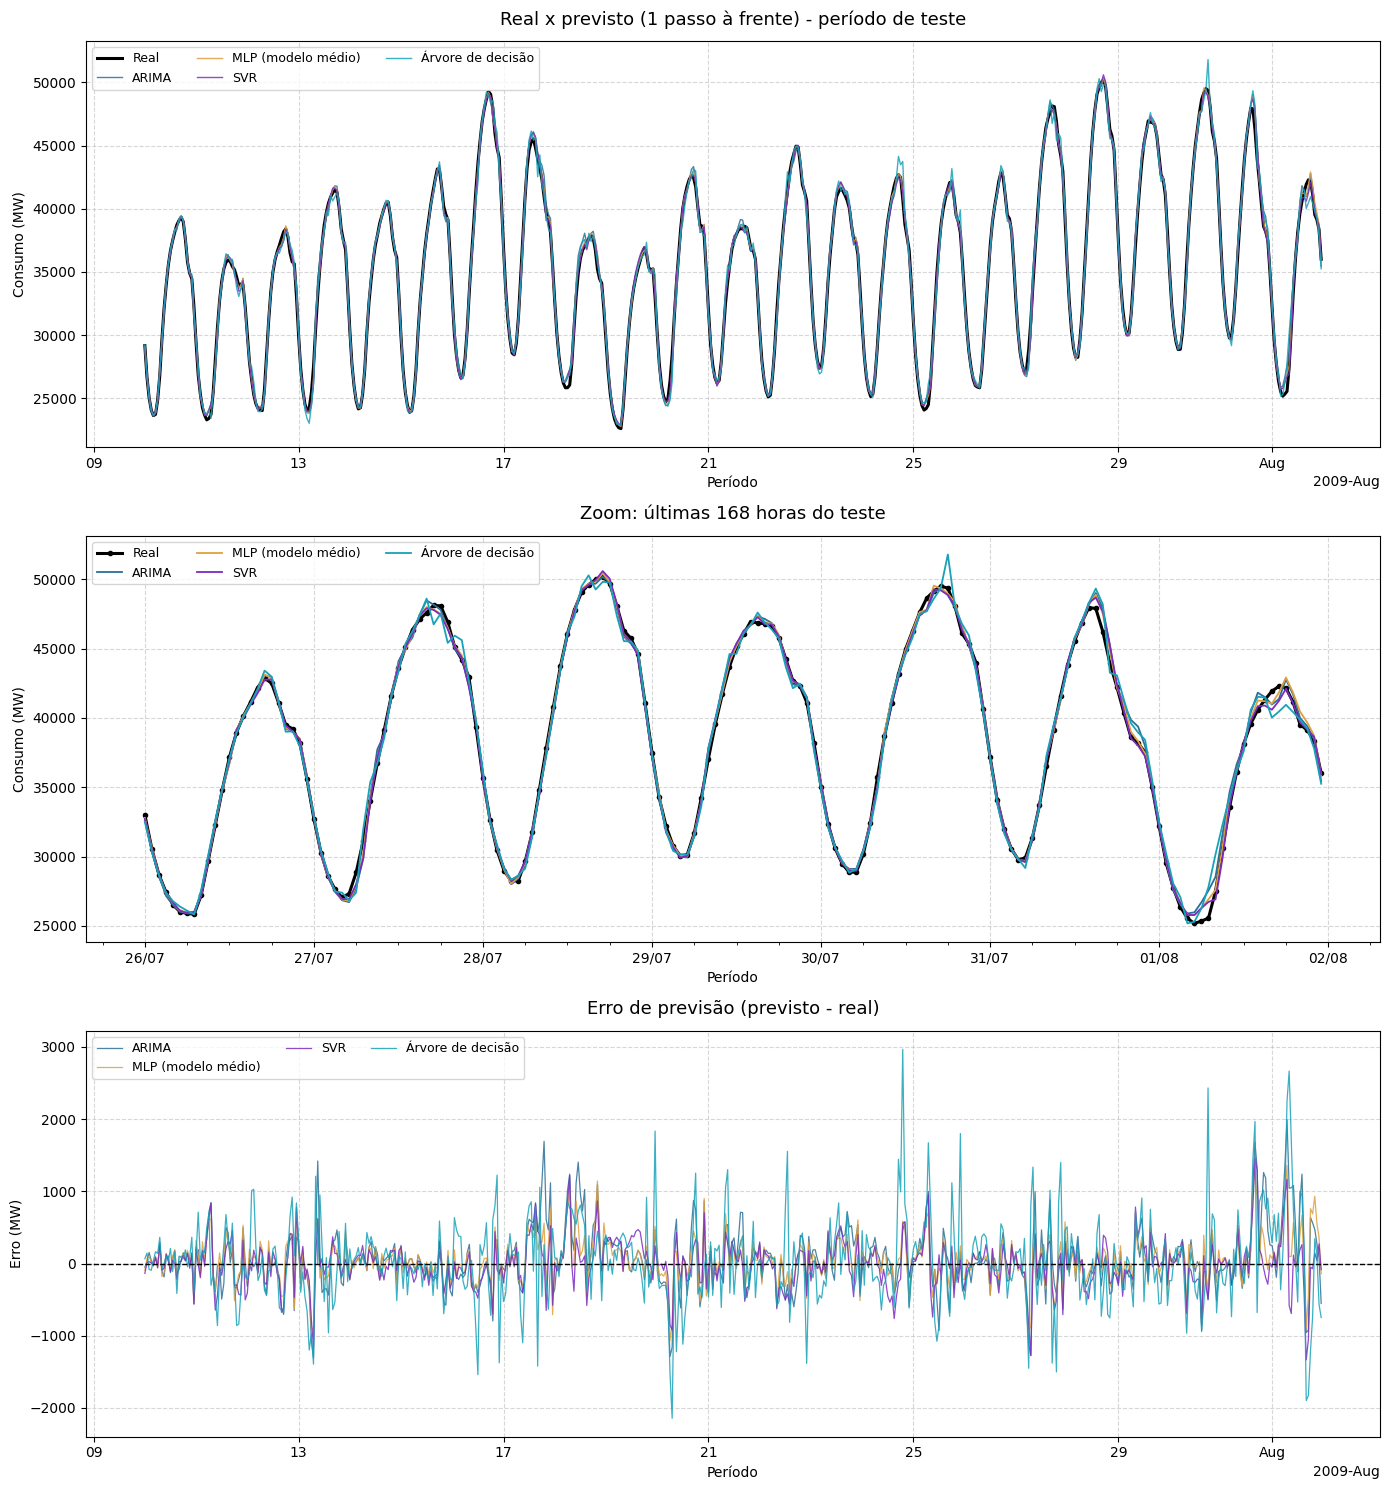

In [ ]:
# Gráficos comparativos
prev = {k: p.loc[y_real.index] for k, p in prev.items()}

cores = {
    'ARIMA': '#2a6f97',
    'MLP (modelo médio)': '#e09f3e',
    'SVR': '#7b2cbf',
    'Árvore de decisão': '#17a2b8'
}
ZOOM = 168               # Última semana do teste

fig, ax = plt.subplots(3, 1, figsize=(14, 15))

# Real x previsto
ax[0].plot(y_real.index, y_real, color='black', linewidth=2.2, label='Real')
for nome, p in prev.items():
    ax[0].plot(p.index, p, color=cores[nome], linewidth=1, alpha=0.85, label=nome)
ax[0].set_title('Real x previsto (1 passo à frente) - período de teste', fontsize=13, pad=12)
ax[0].set_ylabel('Consumo (MW)')
loc = mdates.AutoDateLocator()
ax[0].xaxis.set_major_locator(loc)
ax[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

# Zoom: última semana
idx_z = y_real.index[-ZOOM:]
ax[1].plot(idx_z, y_real.loc[idx_z], color='black', linewidth=2.2,
           marker='o', markersize=3, label='Real')
for nome, p in prev.items():
    ax[1].plot(idx_z, p.loc[idx_z], color=cores[nome], linewidth=1.3, label=nome)
ax[1].set_title(f'Zoom: últimas {ZOOM} horas do teste', fontsize=13, pad=12)
ax[1].set_ylabel('Consumo (MW)')
ax[1].xaxis.set_major_locator(mdates.DayLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax[1].xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))

# Erro de previsão (previsto - real)
for nome, p in prev.items():
    ax[2].plot(p.index, p - y_real, color=cores[nome], linewidth=0.9, alpha=0.85, label=nome)
ax[2].axhline(0, color='black', linestyle='--', linewidth=1)
ax[2].set_title('Erro de previsão (previsto - real)', fontsize=13, pad=12)
ax[2].set_ylabel('Erro (MW)')
loc = mdates.AutoDateLocator()
ax[2].xaxis.set_major_locator(loc)
ax[2].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

for a in ax:
    a.set_xlabel('Período')
    a.grid(True, linestyle='--', alpha=0.5)
    a.legend(loc='upper left', ncol=3, fontsize=9)

plt.tight_layout()
fig.savefig('comparacao_modelos.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
def rmse(p):
    return np.sqrt(((y_real - p.loc[y_real.index]) ** 2).mean())

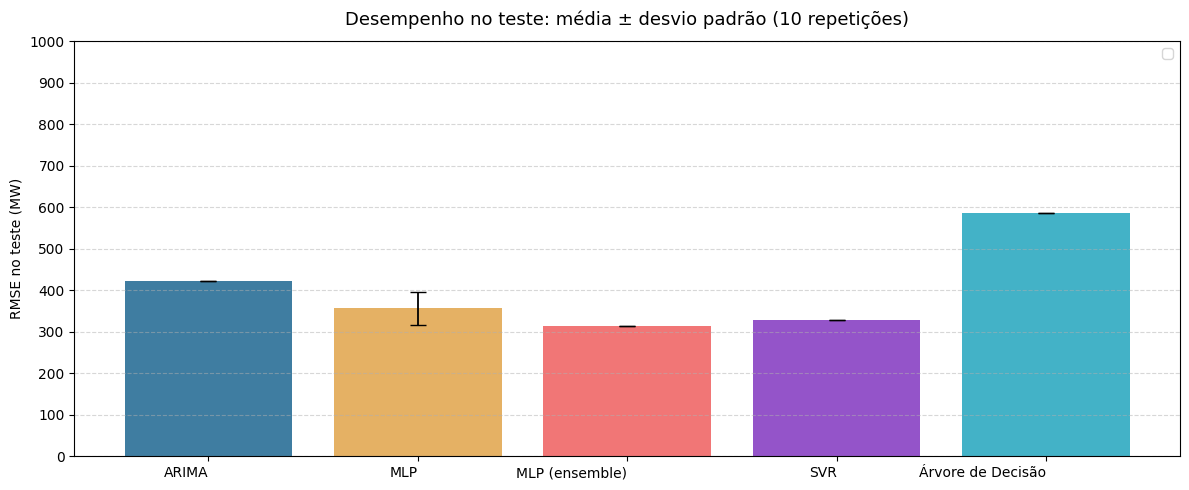

In [ ]:
# RMSE de cada modelo
rmse_mlp = np.array([rmse(preds_mlp[c]) for c in preds_mlp.columns])

nomes   = ['ARIMA', 'MLP', 'MLP (ensemble)', 'SVR', 'Árvore de Decisão']
medias  = [rmse(y_prev), rmse_mlp.mean(), rmse(preds_mlp.mean(axis=1)), rmse(y_prev_svr), rmse(y_prev_tree)]
desvios = [0, rmse_mlp.std(ddof=1), 0, 0, 0]      # só a MLP varia entre sementes
cores   = ['#2a6f97', '#e3a953', '#f06767','#8841c4', '#2eaac1']

ref_24 = df.squeeze().shift(24).loc[df_test.index]
rmse_ref = np.sqrt(((y_real - ref_24) ** 2).mean())

fig, ax = plt.subplots(figsize=(12, 5))

ax.set_ylim(0, 1000)                                  # limites do eixo y
ax.yaxis.set_major_locator(ticker.MultipleLocator(100))   # marcação a cada 100 MW

ax.bar(nomes, medias, yerr=desvios, capsize=6, color=cores, alpha=0.9,
       error_kw={'elinewidth': 1.3, 'ecolor': 'black'})
ax.axhline(rmse_ref, color='gray', linestyle='--', linewidth=1.2,)

ax.set_ylabel('RMSE no teste (MW)')
ax.set_title('Desempenho no teste: média ± desvio padrão (10 repetições)',
             fontsize=13, pad=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.legend()
plt.xticks(rotation=0, ha='right')
plt.tight_layout()
plt.show()

#Série: CO₂ de Mauna Loa

Dataset: https://gml.noaa.gov/ccgg/trends/data.html

## Carregamento dos dados

O período foi fixado em 03/1958 a 12/2025 para que os resultados sejam reprodutíveis (a série ganha um mês novo a cada mês)

In [ ]:
URL_NOAA = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"

def carregar_co2():
    bruto = pd.read_csv(URL_NOAA, comment="#")
    bruto.columns = bruto.columns.str.strip().str.lower()
    datas = pd.to_datetime(dict(year=bruto["year"], month=bruto["month"], day=1))
    return pd.Series(bruto["average"].values, index=datas, name="CO2_ppm")

serie = carregar_co2()

In [ ]:
# paleta e estilo dos gráfico
MAG, MAROON, MAUVE, CORAL, PINK = '#B1114F', '#6A022A', '#C27BA0', '#E06666', '#F2D8E2'
TEAL, PURPLE, GRID, TXT = '#76A5AF', '#8E7CC3', '#E6E6E6', '#4A4A4A'
COR = MAG
_fontes = {f.name for f in font_manager.fontManager.ttflist}
FONTE = next((f for f in ['Liberation Sans', 'Arial', 'Helvetica'] if f in _fontes), 'DejaVu Sans')
plt.rcParams.update({'font.family': [FONTE, 'DejaVu Sans'], 'font.size': 17, 'axes.edgecolor': '#9A9A9A',
                     'axes.labelcolor': TXT, 'xtick.color': TXT, 'ytick.color': TXT,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.9, 'axes.axisbelow': True,
                     'savefig.facecolor': 'white', 'mathtext.default': 'regular'})
br = lambda v, _=None: f'{v:g}'.replace('.', ',').replace('-', '−')
br2 = lambda v, _=None: f'{v:.2f}'.replace('.', ',').replace('-', '−')

In [ ]:
# meses sem medição aparecem como valores negativos (ex.: -99.99): viram NaN e são interpolados
serie[serie < 0] = np.nan

data = (serie.sort_index()
             .loc["1958-03-01":"2025-12-01"]
             .asfreq("MS")          # frequência mensal (início do mês)
             .interpolate())        # preenche eventuais meses sem medição

print("Observações:", len(data), "| período:", data.index.min().strftime('%m/%Y'), "->", data.index.max().strftime('%m/%Y'))
print("Valores faltantes:", int(data.isna().sum()))

Observações: 814 | período: 03/1958 -> 12/2025
Valores faltantes: 0


In [ ]:
# amostragem dos dados p melhorar a visualização (últimos 10 anos)
df = data.loc["2016-01-01":"2025-12-01"]

print(len(df))
print(df.index.to_series().diff().value_counts())   # meses consecutivos: 28 a 31 dias entre as datas

120
31 days    69
30 days    40
28 days     7
29 days     3
Name: count, dtype: int64


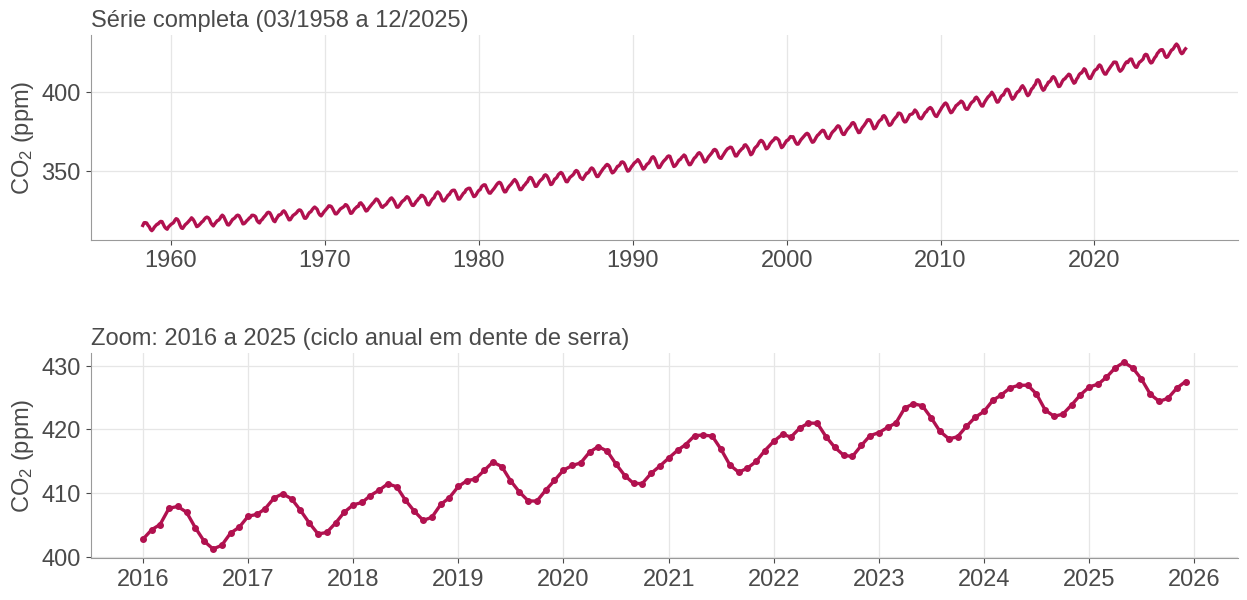

In [ ]:
# plot dos dados em gráfico
fig, axes = plt.subplots(2, 1, figsize=(14.8, 6.8), gridspec_kw={'hspace': 0.55})

# série completa
axes[0].plot(data.index, data.values, color=COR, lw=2.4)
axes[0].xaxis.set_major_locator(mdates.YearLocator(10))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].set_title('Série completa (03/1958 a 12/2025)', loc='left', fontsize=17, color=TXT)

# zoom nos últimos 10 anos, ciclo anual sobre a tendência
axes[1].plot(df.index, df.values, color=COR, lw=2.4, marker='o', ms=4)
axes[1].xaxis.set_major_locator(mdates.YearLocator(1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].set_title('Zoom: 2016 a 2025 (ciclo anual em dente de serra)', loc='left', fontsize=17, color=TXT)

for ax in axes:
    ax.set_ylabel('CO$_2$ (ppm)')
plt.show()

A série tem duas componentes bem visíveis: uma tendência crescente (acúmulo de CO₂ pela queima de combustíveis fósseis) e um ciclo anual em dente de serra, ligado a vegetação do hemisfério norte (o CO₂ cai de maio a outubro, quando as plantas absorvem mais, e sobe de outubro a maio).

## Análise dos dados

### Características estatísticas (série completa)

In [ ]:
# estatísticas descritivas
print(data.describe().round(2))
print("Variância:", round(data.var(), 2))

# tendência: inclinação da reta ajustada (ppm por ano)
anos = np.arange(len(data)) / 12
print("Inclinação da tendência linear:", round(np.polyfit(anos, data.values, 1)[0], 2), "ppm/ano")

# estacionariedade (ADF: H0 = não estacionária | KPSS: H0 = estacionária)
def testar_estacionariedade(x, nome):
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    print(f"{nome:<34} ADF p = {p_adf:.4f} ({'estacionária' if p_adf < 0.05 else 'NÃO estacionária'}) | "
          f"KPSS p = {p_kpss:.3f} ({'estacionária' if p_kpss >= 0.05 else 'NÃO estacionária'})")

testar_estacionariedade(data, "Série original")

count    814.00
mean     360.69
std       32.92
min      312.42
25%      330.92
50%      355.90
75%      386.77
max      430.51
Name: CO2_ppm, dtype: float64
Variância: 1083.55
Inclinação da tendência linear: 1.66 ppm/ano
Série original                     ADF p = 1.0000 (NÃO estacionária) | KPSS p = 0.010 (NÃO estacionária)


/tmp/ipykernel_1388/3364597051.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf = adfuller(x, autolag='AIC')[1]
/tmp/ipykernel_1388/3364597051.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression='c', nlags='auto')[1]
/tmp/ipykernel_1388/3364597051.py:12: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPS

### Decomposição (STL): tendência, sazonalidade e resíduo

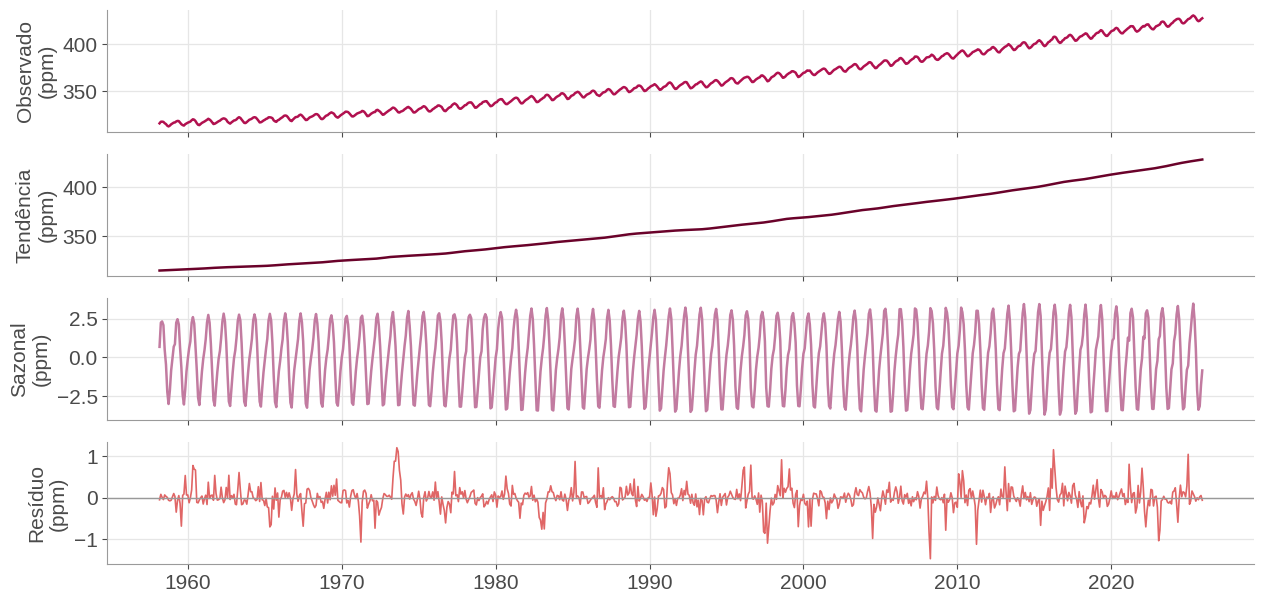

Força da sazonalidade: 0.984 | Força da tendência: 1.000
Pico sazonal em Mai (+2.99 ppm) | vale em Out (-3.25 ppm)


In [ ]:
stl = STL(data, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(14.8, 7.2), sharex=True, gridspec_kw={'hspace': 0.18})
for ax, (y, rotulo, cor) in zip(axes, [(data.values, 'Observado', MAG), (stl.trend.values, 'Tendência', MAROON),
                                       (stl.seasonal.values, 'Sazonal', MAUVE), (stl.resid.values, 'Resíduo', CORAL)]):
    ax.plot(data.index, y, color=cor, lw=1.8 if rotulo != 'Resíduo' else 1.2)
    ax.set_ylabel(rotulo + '\n(ppm)', fontsize=15)
    ax.tick_params(labelsize=15)
axes[3].axhline(0, color='#999', lw=1)
axes[3].xaxis.set_major_locator(mdates.YearLocator(10))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.show()

# força da sazonalidade e da tendência (0 = inexistente, 1 = domina a série)
forca_sazonal = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
forca_tendencia = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
print(f"Força da sazonalidade: {forca_sazonal:.3f} | Força da tendência: {forca_tendencia:.3f}")

# perfil sazonal médio (efeito de cada mês, em ppm)
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
perfil = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print(f"Pico sazonal em {meses[perfil.idxmax() - 1]} ({perfil.max():+.2f} ppm) | vale em {meses[perfil.idxmin() - 1]} ({perfil.min():+.2f} ppm)")

### Correlogramas (ACF e PACF)

Os modelos estatísticos não tem conjunto de validação: treino e validação são concatenados (75% iniciais). A identificação da ordem usa esse trecho, para não "espiar" o teste.

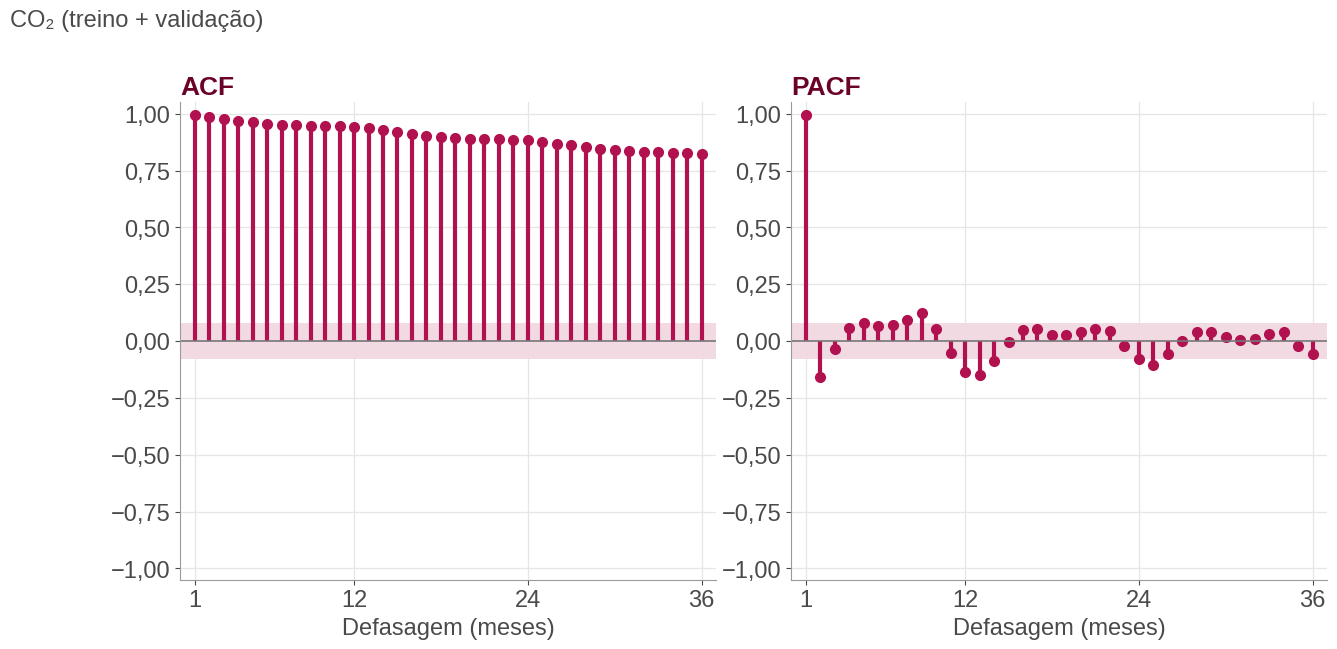

In [ ]:
# modelos estatísticos: sem validação -> "treino" = treino (50%) + validação (25%) = 75% iniciais
n_treino = int(len(data) * 0.75)
treino = data.iloc[:n_treino]

def plot_acf_pacf(x, lags, titulo, ylim=(-1.05, 1.05), destaques=None):
    """ACF e PACF em hastes, com banda de ±1,96/√n (hastes dentro da banda ≈ 0).
    destaques = (lags da ACF, lags da PACF) a anotar no gráfico."""
    A = acf(x, nlags=lags)
    P = pacf(x, nlags=lags, method='ywm')
    ci = 1.96 / np.sqrt(len(x))
    fig, axes = plt.subplots(1, 2, figsize=(14.8, 6.2), gridspec_kw={'wspace': 0.14})
    for ax, v, nome in [(axes[0], A, 'ACF'), (axes[1], P, 'PACF')]:
        ax.axhspan(-ci, ci, color=PINK, alpha=0.95, lw=0)
        ax.vlines(range(1, lags + 1), 0, v[1:], color=MAG, lw=3)
        ax.plot(range(1, lags + 1), v[1:], 'o', color=MAG, ms=7)
        ax.axhline(0, color='#777', lw=1.2)
        ax.set_ylim(*ylim)
        ax.set_xlim(0, lags + 1)
        ax.set_xticks([1] + list(range(12, lags + 1, 12)))
        ax.set_title(nome, loc='left', fontsize=19, color=MAROON, fontweight='bold')
        ax.set_xlabel('Defasagem (meses)')
        ax.yaxis.set_major_formatter(FuncFormatter(br2))
    if destaques:
        for lag in destaques[0]:
            axes[0].annotate(f'lag {lag}', (lag, A[lag]), xytext=(lag + 1.2, A[lag] - 0.028), fontsize=16, color=MAROON, fontweight='bold')
        for lag in destaques[1]:
            axes[1].annotate(f'lag {lag}', (lag, P[lag]), xytext=(lag + 1.2, P[lag] - 0.03), fontsize=16, color=MAROON, fontweight='bold')
    fig.suptitle(titulo, x=0.01, y=1.03, ha='left', fontsize=17, color=TXT)
    plt.show()

# 36 lags = três ciclos anuais
plot_acf_pacf(treino, 36, "CO₂ (treino + validação)")

A ACF decai muito lentamente (com ondulações a cada 12 lags) e a PACF é quase 1 no lag 1: o comportamento típico de uma série com tendência e sazonalidade, ou seja, não estacionária.

### Remoção de sazonalidade

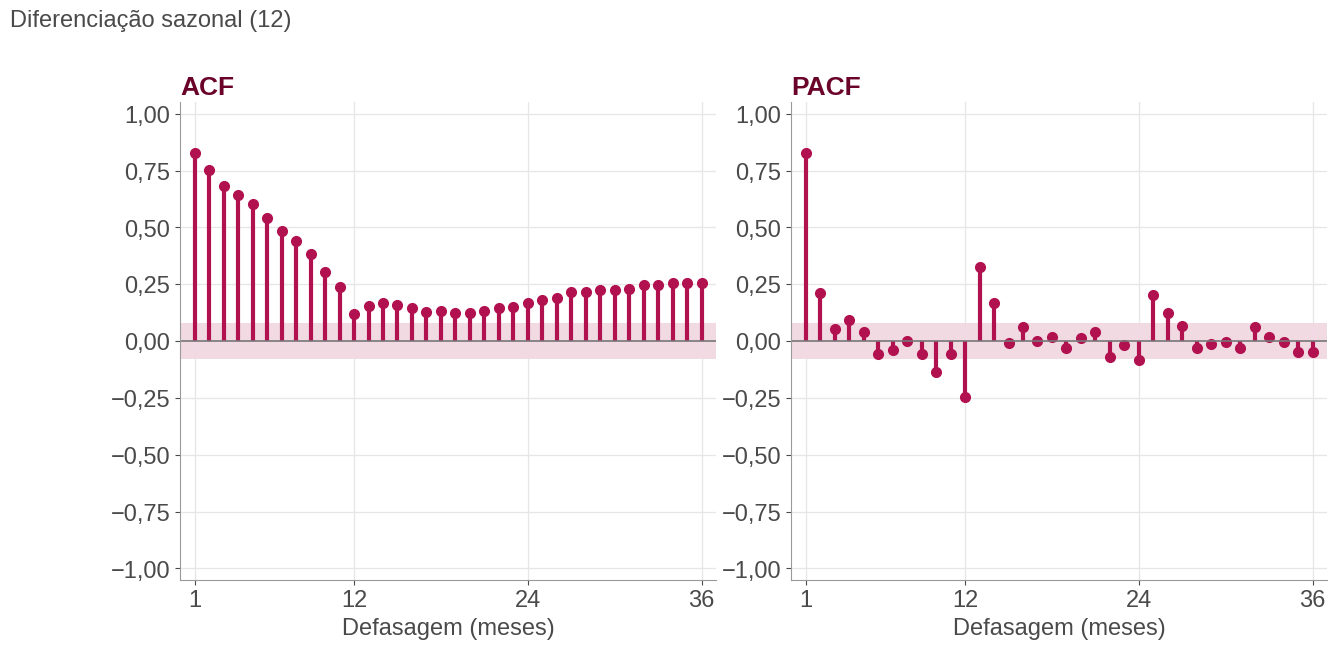

In [ ]:
noseason_df = treino.diff(12).dropna()
# como os dados são mensais, 12 meses = 1 ano, então a diferenciação sazonal é de lag 12

plot_acf_pacf(noseason_df, 36, "Diferenciação sazonal (12)")

A diferença sazonal remove o ciclo anual, mas a ACF ainda decai devagar: sobrou a tendência.

### Remoção de tendência

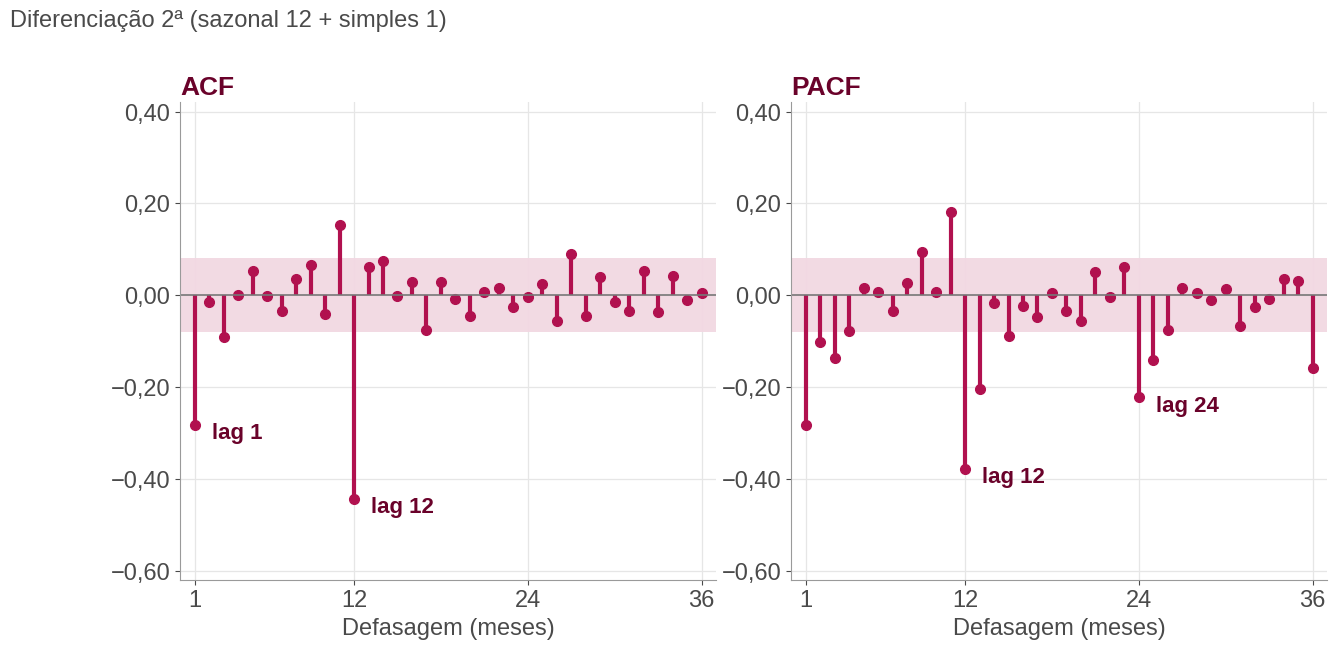

In [ ]:
# aplicação da diferenciação em 1
notendency_df = noseason_df.diff(1).dropna()

plot_acf_pacf(notendency_df, 36, "Diferenciação 2ª (sazonal 12 + simples 1)", ylim=(-0.62, 0.42),
              destaques=((1, 12), (12, 24)))     # lags que identificam o MA(1) e o MA sazonal(1)

Depois das duas diferenciações, a ACF mostra picos negativos nos lags 1 e 12 (e um pico positivo menor no lag 11), e a PACF decai nos múltiplos de 12. Essa é a assinatura de uma média móvel simples MA(1) combinada com uma média móvel sazonal MA(1): o modelo clássico SARIMA(0,1,1)(0,1,1)₁₂ (airline model). Variações com um termo a mais serão testadas na Parte I.

### Verificação de resíduo

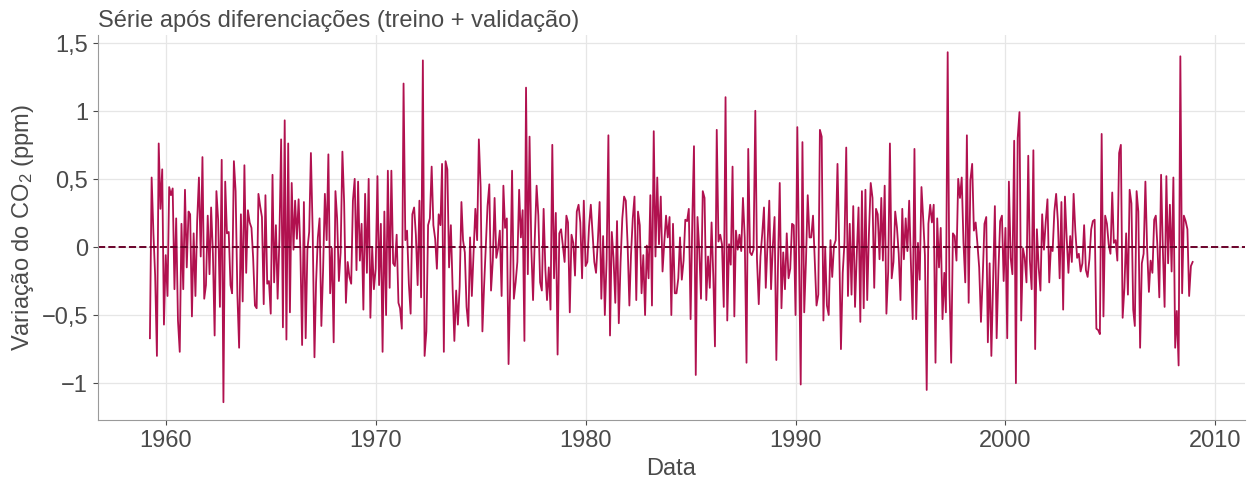

Após diferenciação sazonal (12)    ADF p = 0.0027 (estacionária) | KPSS p = 0.010 (NÃO estacionária)
Após sazonal (12) + simples (1)    ADF p = 0.0000 (estacionária) | KPSS p = 0.100 (estacionária)


/tmp/ipykernel_1388/3364597051.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf = adfuller(x, autolag='AIC')[1]
/tmp/ipykernel_1388/3364597051.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression='c', nlags='auto')[1]
/tmp/ipykernel_1388/3364597051.py:12: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPS

In [ ]:
# plotagem do que sobrou da série
fig, ax = plt.subplots(figsize=(14.8, 5))
ax.plot(notendency_df.index, notendency_df.values, color=COR, lw=1.3)
ax.axhline(0, color=MAROON, linestyle='--', lw=1.4)
ax.set_title('Série após diferenciações (treino + validação)', loc='left', fontsize=17, color=TXT)
ax.set_xlabel('Data')
ax.set_ylabel('Variação do CO$_2$ (ppm)')
ax.yaxis.set_major_formatter(FuncFormatter(br))
plt.show()

testar_estacionariedade(noseason_df, "Após diferenciação sazonal (12)")
testar_estacionariedade(notendency_df, "Após sazonal (12) + simples (1)")

A série diferenciada oscila em torno de zero com variância estável e passa nos testes de estacionariedade. Conclusão da identificação: d = 1, D = 1, s = 12, com termos de média móvel (MA) em lag 1 e lag 12.

## Pré-processamento

### Hold-out

Separação temporal seguindo a divisão: 50% treinamento, 25% validação e 25% teste. Os modelos de ML usam as três partes (hiperparâmetros escolhidos na validação). Para os modelos estatísticos, neste protocolo, treino e validação são concatenados, utilizando os 75% iniciais da série para ajuste e seleção via critérios estatísticos. Os 25% finais permanecem reservados exclusivamente para teste.

Total: 814 instâncias | treino: 407 | validação: 203 | teste: 204
Treino     03/1958 -> 01/1992  (407 meses)
Validação  02/1992 -> 12/2008  (203 meses)
Teste      01/2009 -> 12/2025  (204 meses)


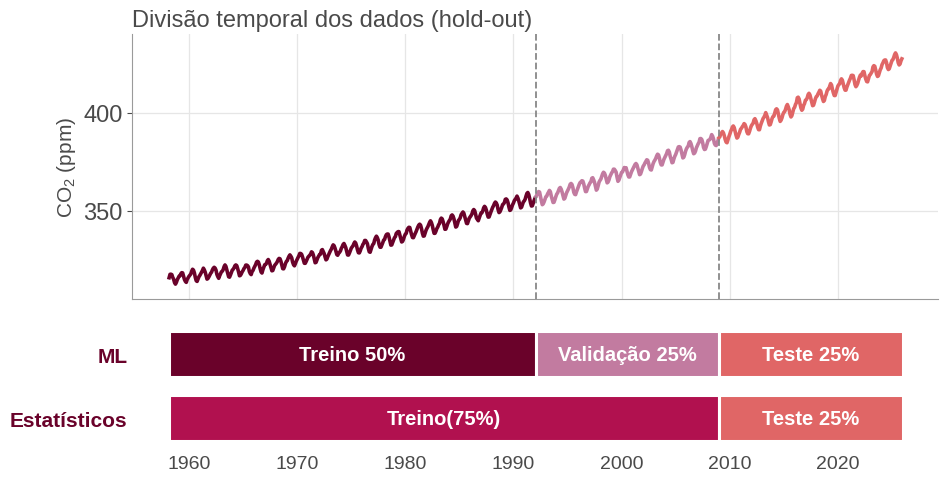

In [ ]:
n = len(data)
a = int(n * 0.50)
b = int(n * 0.75)

df_train = data.iloc[:a]
df_val = data.iloc[a:b]
df_test = data.iloc[b:]

print(f"Total: {n} instâncias | treino: {len(df_train)} | validação: {len(df_val)} | teste: {len(df_test)}")
for nome, parte in [("Treino", df_train), ("Validação", df_val), ("Teste", df_test)]:
    print(f"{nome:<10} {parte.index.min().strftime('%m/%Y')} -> {parte.index.max().strftime('%m/%Y')}  ({len(parte)} meses)")

# em cima, a série por partição
# embaixo, como cada família de modelos usa os dados
fig = plt.figure(figsize=(10.4, 5.4))
gs = fig.add_gridspec(2, 1, height_ratios=[3.1, 1.5], hspace=0.12)
ax = fig.add_subplot(gs[0])
bx = fig.add_subplot(gs[1], sharex=ax)
for parte, cor in [(df_train, MAROON), (df_val, MAUVE), (df_test, CORAL)]:
    ax.plot(parte.index, parte.values, color=cor, lw=2.6)
for k in (a, b):
    ax.axvline(data.index[k], color='#888', ls='--', lw=1.3)
ax.set_title('Divisão temporal dos dados (hold-out)', loc='left', fontsize=17, color=TXT)
ax.set_ylim(305, 440)
ax.set_ylabel('CO$_2$ (ppm)', fontsize=15)
ax.tick_params(labelsize=14, labelbottom=False, axis='x', length=0)

x0, xa, xb, xn = (mdates.date2num(data.index[0]), mdates.date2num(data.index[a]),
                  mdates.date2num(data.index[b]), mdates.date2num(data.index[-1]) + 31)
def barra(y, ini, fim, cor, texto):
    bx.add_patch(Rectangle((ini, y - 0.36), fim - ini, 0.72, facecolor=cor, edgecolor='white', lw=2.2))
    bx.text((ini + fim) / 2, y, texto, ha='center', va='center', fontsize=14.5, fontweight='bold', color='white')
barra(1.0, x0, xa, MAROON, 'Treino 50%'); barra(1.0, xa, xb, MAUVE, 'Validação 25%'); barra(1.0, xb, xn, CORAL, 'Teste 25%')   # ML
barra(0.0, x0, xb, MAG, 'Treino(75%)'); barra(0.0, xb, xn, CORAL, 'Teste 25%')                                   # estatísticos
bx.set_ylim(-0.5, 1.5)
bx.set_yticks([0, 1])
bx.set_yticklabels(['Estatísticos', 'ML'], fontsize=15, fontweight='bold', color=MAROON)
bx.grid(False)
bx.spines['left'].set_visible(False)
bx.spines['bottom'].set_visible(False)
bx.tick_params(axis='y', length=0)
bx.xaxis.set_major_locator(mdates.YearLocator(10))
bx.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
bx.tick_params(axis='x', labelsize=14, length=0)
bx.set_xlim(ax.get_xlim())
plt.show()

### Normalização

Min-Max para o intervalo [0, 1], ajustado só no treino (50% iniciais, para não vazar informação do futuro). A mesma escala vale para todos os modelos, inclusive os estatísticos, para que as métricas normalizadas sejam comparáveis.

In [ ]:
minimo, maximo = df_train.min(), df_train.max()
amp = maximo - minimo                      # amplitude do treino em ppm (usada para voltar à escala original)

data_norm = (data - minimo) / amp
desnormalizar = lambda z: z * amp + minimo

print(f"Treino: min = {minimo:.2f} ppm, max = {maximo:.2f} ppm (amplitude {amp:.2f} ppm)")
for nome, ini, fim in [("Treino", 0, a), ("Validação", a, b), ("Teste", b, n)]:
    parte = data_norm.iloc[ini:fim]
    print(f"{nome:<10} escalado em [{parte.min():.2f}, {parte.max():.2f}]")

Treino: min = 312.42 ppm, max = 359.23 ppm (amplitude 46.81 ppm)
Treino     escalado em [0.00, 1.00]
Validação  escalado em [0.87, 1.63]
Teste      escalado em [1.54, 2.52]


Por causa da tendência, a validação já ultrapassa 1 e o teste fica inteiro acima de 1 (o CO₂ desses períodos é maior que o do treino). Modelos como SVR com kernel RBF, Árvore de Decisão e KNN não extrapolam, então os modelos de ML não vão prever o nível: vão prever a variação da série já diferenciada, e o nível é reconstruído depois.

### Diferenciação (série usada pelos modelos de ML)

Mesma lógica da Remoção de sazonalidade e tendência: diferença sazonal (12) e depois simples (1), agora sobre a série normalizada. Os modelos estatísticos (SARIMAX) fazem essa diferenciação internamente com `d = 1` e `D = 1`.

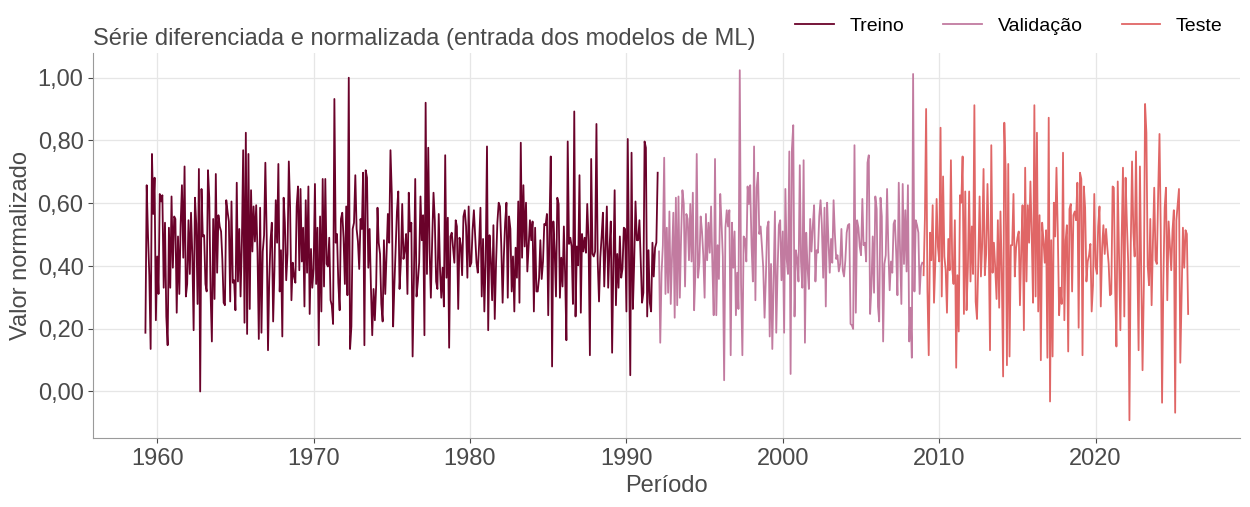

In [ ]:
# diferenciação sazonal (12) + simples (1) da série normalizada
w = data_norm.diff(1).diff(12)
INICIO = 13                                   # as 13 primeiras posições ficam NaN

# Min-Max novamente, só no treino: entrada e saída dos modelos de ML ficam em escala comparável
w_min, w_max = w.iloc[INICIO:a].min(), w.iloc[INICIO:a].max()
wn = (w - w_min) / (w_max - w_min)

fig, ax = plt.subplots(figsize=(14.8, 5))
ax.plot(wn.iloc[INICIO:a].index, wn.iloc[INICIO:a], color=MAROON, lw=1.3, label='Treino')
ax.plot(wn.iloc[a:b].index, wn.iloc[a:b], color=MAUVE, lw=1.3, label='Validação')
ax.plot(wn.iloc[b:].index, wn.iloc[b:], color=CORAL, lw=1.3, label='Teste')
ax.set_title('Série diferenciada e normalizada (entrada dos modelos de ML)', loc='left', fontsize=17, color=TXT)
ax.set_xlabel('Período')
ax.set_ylabel('Valor normalizado')
ax.yaxis.set_major_formatter(FuncFormatter(br2))
ax.legend(ncol=3, loc='lower right', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=14)   # legenda acima do gráfico, sem cobrir a série
plt.show()

### Funções de avaliação (usadas em todos os modelos)

Todos os modelos fazem previsão 1 passo à frente no teste: a previsão de cada mês usa apenas valores observados até o mês anterior. As métricas são calculadas na escala original (ppm) e também normalizadas pela amplitude do treino (escala [0, 1]).

In [ ]:
v = data_norm.values
N_REP = 10                                 # número de repetições por modelo
idx_teste = data.index[b:]
real_teste = data.values[b:]

def rmse_ppm(real_norm, prev_norm):
    return np.sqrt(np.mean((real_norm - prev_norm) ** 2)) * amp

def metricas(real_ppm, prev_ppm):
    e = real_ppm - prev_ppm
    return {'RMSE': np.sqrt(np.mean(e ** 2)) / amp,       # normalizado pela amplitude do treino
            'MAE': np.mean(np.abs(e)) / amp,
            'MAPE (%)': np.mean(np.abs(e / real_ppm)) * 100,
            'RMSE (ppm)': np.sqrt(np.mean(e ** 2))}

RESULTADOS = {}   # nome -> previsões do teste (N_REP x n_teste, em ppm), métricas por repetição e configuração

def registrar(nome, prevs_ppm, config):
    prevs_ppm = np.asarray(prevs_ppm)
    tabela = pd.DataFrame([metricas(real_teste, p) for p in prevs_ppm])
    RESULTADOS[nome] = {'prev': prevs_ppm, 'metricas': tabela, 'config': config}
    print(f"{nome}: RMSE teste = {tabela['RMSE (ppm)'].mean():.4f} ppm (± {tabela['RMSE (ppm)'].std():.4f})")

## Parte I: Modelos estatísticos

Como a série é mensal, usamos o termo sazonal do `SARIMAX` (`D = 1`, `s = 12`), que equivale a pré-diferenciar e já devolve as previsões na escala da série (sem reconstruir). O parâmetro `concentrate_scale=True` melhora a estabilidade numérica (a série em [0, 1] tem variância residual minúscula).

**Protocolo:** treino + validação concatenados (75%) -> identificação por ACF/PACF e escolha da ordem por critério de informação (AIC/BIC) e diagnóstico dos resíduos (Ljung-Box) -> modelo ajustado nos 75% -> previsão 1 passo à frente nos 25% de teste.

In [ ]:
def ajustar_sarima(ordem, sazonal, n_ajuste):
    return SARIMAX(v[:n_ajuste], order=ordem, seasonal_order=sazonal, trend='n',
                   concentrate_scale=True).fit(disp=False, maxiter=300)

def prever_1passo(modelo, n_total):
    # parâmetros FIXOS; cada previsão usa só valores observados até t-1 (previsão 1 passo à frente)
    return np.asarray(modelo.apply(v[:n_total]).fittedvalues)

### Metodologia de Box & Jenkins

In [ ]:
# parâmetros do SARIMA (identificados pelos gráficos da diferenciação):
# p = 0, 1, 2   # PACF decai, sem corte nítido -> parte autorregressiva opcional
# d = 1         # diferenciação simples (tendência)
# q = 1, 2, 3   # ACF com pico negativo no lag 1 -> MA(1); 2 e 3 para testagem
# P = 0, 1      # parte autorregressiva sazonal opcional
# D = 1         # diferenciação sazonal (s = 12)
# Q = 1, 2      # ACF com pico negativo no lag 12 -> MA sazonal(1); 2 para testagem

# Combinações testadas: (p, d, q) e (P, D, Q, s)
testes = [((0, 1, 1), (0, 1, 1, 12)),    # airline model
          ((1, 1, 1), (0, 1, 1, 12)),
          ((0, 1, 2), (0, 1, 1, 12)),
          ((2, 1, 1), (0, 1, 1, 12)),
          ((1, 1, 0), (0, 1, 1, 12)),
          ((0, 1, 3), (0, 1, 1, 12)),
          ((0, 1, 1), (1, 1, 1, 12)),
          ((1, 1, 1), (1, 1, 1, 12)),
          ((0, 1, 1), (0, 1, 2, 12))]

# SEM VALIDAÇÃO: todos os candidatos são ajustados em TREINO + VALIDAÇÃO (75% iniciais)
CRITERIO_BJ = "BIC"      # critério de informação para escolher entre os candidatos: "BIC" ou "AIC"

linhas_bj = []
for ordem, sazonal in testes:
    m = ajustar_sarima(ordem, sazonal, b)                     # ajuste nos 75% iniciais (treino + validação)
    k = len(m.params)                                          # n de parâmetros estimados
    # Ljung-Box nos resíduos (sem os 13 primeiros, que vem da diferenciação)
    lb = acorr_ljungbox(m.resid[13:], lags=[12, 24], model_df=k)["lb_pvalue"].values
    linhas_bj.append({"Modelo": f"SARIMA{ordem}{sazonal}", "ordem": ordem, "sazonal": sazonal,
                      "AIC": m.aic, "BIC": m.bic,
                      "Ljung-Box p (12)": lb[0], "Ljung-Box p (24)": lb[1]})

tabela_bj = pd.DataFrame(linhas_bj)
tabela_bj["Resíduos OK"] = (tabela_bj["Ljung-Box p (12)"] > 0.05) & (tabela_bj["Ljung-Box p (24)"] > 0.05)
# critério: entre os candidatos com resíduos aprovados no Ljung-Box (p > 0,05), o de menor BIC (parcimônia)
tabela_bj = tabela_bj.sort_values(["Resíduos OK", CRITERIO_BJ], ascending=[False, True]).reset_index(drop=True)
print(tabela_bj.drop(columns=["ordem", "sazonal"])
               .round({"AIC": 1, "BIC": 1, "Ljung-Box p (12)": 3, "Ljung-Box p (24)": 3}).to_string(index=False))

ordem_bj, sazonal_bj = tabela_bj.loc[0, "ordem"], tabela_bj.loc[0, "sazonal"]
print(f"\nModelo escolhido (Box & Jenkins, menor {CRITERIO_BJ} entre os aprovados no Ljung-Box):", f"SARIMA{ordem_bj}{sazonal_bj}")

                      Modelo     AIC     BIC  Ljung-Box p (12)  Ljung-Box p (24)  Resíduos OK
SARIMA(0, 1, 1)(0, 1, 1, 12) -4300.8 -4287.6             0.428             0.542         True
SARIMA(1, 1, 1)(0, 1, 1, 12) -4301.1 -4283.6             0.654             0.656         True
SARIMA(0, 1, 2)(0, 1, 1, 12) -4300.6 -4283.0             0.567             0.613         True
SARIMA(0, 1, 1)(0, 1, 2, 12) -4298.9 -4281.3             0.348             0.492         True
SARIMA(0, 1, 1)(1, 1, 1, 12) -4298.9 -4281.3             0.347             0.492         True
SARIMA(0, 1, 3)(0, 1, 1, 12) -4300.1 -4278.2             0.712             0.671         True
SARIMA(2, 1, 1)(0, 1, 1, 12) -4299.9 -4277.9             0.677             0.661         True
SARIMA(1, 1, 1)(1, 1, 1, 12) -4299.3 -4277.3             0.583             0.620         True
SARIMA(1, 1, 0)(0, 1, 1, 12) -4288.8 -4275.6             0.020             0.114        False

Modelo escolhido (Box & Jenkins, menor BIC entre os aprovad

Dos nove candidatos, oito passam no teste de Ljung-Box (p > 0,05 nos lags 12 e 24: sem autocorrelação residual); o SARIMA(1,1,0)(0,1,1)₁₂ é reprovado (p = 0,02 no lag 12), o que mostra que o termo MA(1) é necessário. Entre os aprovados, o escolhido é o de menor BIC, que penaliza complexidade (parcimônia). Para escolher por AIC, basta

**Diagnóstico dos resíduos** do modelo escolhido:

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  610
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                2153.407
Date:                            Tue, 06 Oct 2026   AIC                          -4300.813
Time:                                    17:54:31   BIC                          -4287.637
Sample:                                         0   HQIC                         -4295.683
                                            - 610   Scale                            0.000
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3675      0.036    -10.287      0.000      -0.438      -0.298
ma.S.L12      -0.8699      0.023   

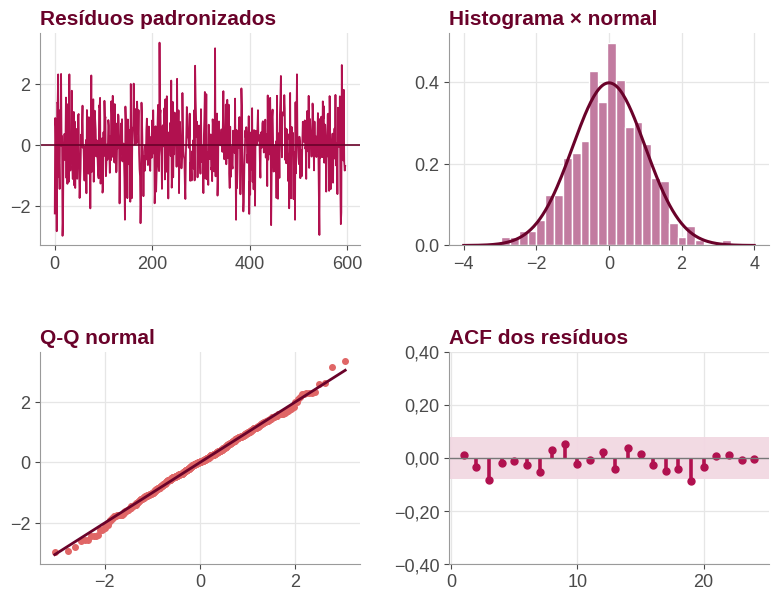

In [ ]:
# modelo escolhido, TREINO + VALIDAÇÃO (75%)
modelo_bj = ajustar_sarima(ordem_bj, sazonal_bj, b)
print(modelo_bj.summary())

# diagnóstico dos resíduos (sem os 13 primeiros, que vem da diferenciação)
res = np.asarray(modelo_bj.resid)[13:]
zr = (res - res.mean()) / res.std()
fig, axes = plt.subplots(2, 2, figsize=(9.4, 6.9), gridspec_kw={'hspace': 0.5, 'wspace': 0.28})
axes[0, 0].plot(zr, color=MAG, lw=1.3)
axes[0, 0].axhline(0, color=MAROON, lw=1.2)
axes[0, 0].set_title('Resíduos padronizados', fontsize=15, loc='left', color=MAROON, fontweight='bold')
axes[0, 1].hist(zr, bins=26, density=True, color=MAUVE, edgecolor='white')
xs = np.linspace(-4, 4, 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs), color=MAROON, lw=2.2)
axes[0, 1].set_title('Histograma × normal', fontsize=15, loc='left', color=MAROON, fontweight='bold')
(osm, osr), (inclinacao, intercepto, _) = stats.probplot(zr, dist='norm')
axes[1, 0].plot(osm, osr, 'o', color=CORAL, ms=4)
axes[1, 0].plot(osm, inclinacao * osm + intercepto, color=MAROON, lw=2)
axes[1, 0].set_title('Q-Q normal', fontsize=15, loc='left', color=MAROON, fontweight='bold')
Ar = acf(zr, nlags=24)
cir = 1.96 / np.sqrt(len(zr))
axes[1, 1].axhspan(-cir, cir, color=PINK, alpha=0.95, lw=0)
axes[1, 1].vlines(range(1, 25), 0, Ar[1:], color=MAG, lw=2.6)
axes[1, 1].plot(range(1, 25), Ar[1:], 'o', color=MAG, ms=5)
axes[1, 1].axhline(0, color='#777', lw=1)
axes[1, 1].set_ylim(-0.4, 0.4)
axes[1, 1].set_title('ACF dos resíduos', fontsize=15, loc='left', color=MAROON, fontweight='bold')
for ax in axes.flat:
    ax.tick_params(labelsize=13)
for ax, fmt in [(axes[0, 0], br), (axes[1, 0], br), (axes[1, 1], br2)]:
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))
plt.show()

In [ ]:
# previsão 1 passo à frente no TESTE com o modelo ajustado nos 75% (treino + validação)
prev_teste_bj = desnormalizar(prever_1passo(modelo_bj, n)[b:])

# modelo estatístico determinístico: as 10 repetições são idênticas (desvio padrão = 0)
registrar("I. Box & Jenkins", np.tile(prev_teste_bj, (N_REP, 1)), f"SARIMA{ordem_bj}{sazonal_bj}")

I. Box & Jenkins: RMSE teste = 0.3475 ppm (± 0.0000)


### Auto-ARIMA

Seleção automática das ordens (p, d, q)(P, D, Q)₁₂ por critério de informação (AIC), usando só o treino.

In [ ]:
try:
    import pmdarima as pm
    TEM_PMDARIMA = True
except ImportError:
    TEM_PMDARIMA = False
    print("pmdarima não encontrado (pip install pmdarima): usando busca em grade por AIC no lugar.")

if TEM_PMDARIMA:
    auto = pm.auto_arima(v[:b], seasonal=True, m=12,
                         start_p=0, start_q=0, max_p=3, max_q=3,
                         start_P=0, start_Q=0, max_P=2, max_Q=2,
                         d=None, D=None,                    # d e D escolhidos por testes de raiz unitária
                         information_criterion='aic', stepwise=True, trace=True,
                         error_action='ignore', suppress_warnings=True, maxiter=200,
                         sarimax_kwargs={'concentrate_scale': True})
    ordem_auto, sazonal_auto = tuple(int(x) for x in auto.order), tuple(int(x) for x in auto.seasonal_order)
else:
    melhor = None
    for p in range(4):
        for q in range(4):
            for P in range(3):
                for Q in range(3):
                    try:
                        m = ajustar_sarima((p, 1, q), (P, 1, Q, 12), b)
                    except Exception:
                        continue
                    if melhor is None or m.aic < melhor[0]:
                        melhor = (m.aic, (p, 1, q), (P, 1, Q, 12))
    _, ordem_auto, sazonal_auto = melhor

print("\nAuto-ARIMA escolheu:", f"SARIMA{ordem_auto}{sazonal_auto}", "(critério AIC, 75% de treino + validação)")

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=-2721.904, Time=0.38 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=inf, Time=3.51 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=-3372.063, Time=1.21 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=inf, Time=nan sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=-3087.775, Time=0.58 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=-4283.389, Time=2.82 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=-4057.400, Time=1.47 sec
 ARIMA(0,1,1)(2,0,1)[12] intercept   : AIC=-4276.820, Time=10.94 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=inf, Time=8.36 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=-3541.323, Time=2.51 sec
 ARIMA(0,1,1)(2,0,0)[12] intercept   : AIC=-4194.719, Time=3.75 sec
 ARIMA(0,1,1)(2,0,2)[12] intercept   : AIC=-3079.470, Time=4.17 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=-4260.639, Time=2.57 sec
 ARIMA(1,1,1)(1,0,1)[12] intercept   : AIC=-4318.417, Time=2.75 sec
 ARIMA(1,1,1)(0,0,1)[12

In [ ]:
# 75% (treino + validação) e previsão 1 passo à frente no TESTE
m_auto = ajustar_sarima(ordem_auto, sazonal_auto, b)
prev_teste_auto = desnormalizar(prever_1passo(m_auto, n)[b:])

print(f"Box & Jenkins: SARIMA{ordem_bj}{sazonal_bj}  (d = {ordem_bj[1]}, D = {sazonal_bj[1]})")
print(f"Auto-ARIMA:    SARIMA{ordem_auto}{sazonal_auto}  (d = {ordem_auto[1]}, D = {sazonal_auto[1]})")
registrar("II. Auto-ARIMA", np.tile(prev_teste_auto, (N_REP, 1)), f"SARIMA{ordem_auto}{sazonal_auto}")

Box & Jenkins: SARIMA(0, 1, 1)(0, 1, 1, 12)  (d = 1, D = 1)
Auto-ARIMA:    SARIMA(1, 1, 1)(1, 0, 1, 12)  (d = 1, D = 0)
II. Auto-ARIMA: RMSE teste = 0.3453 ppm (± 0.0000)


In [ ]:
# coeficientes estimados do Auto-ARIMA (ajustado nos 75%)
print(m_auto.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2137      0.056      3.803      0.000       0.104       0.324
ma.L1         -0.5429      0.055     -9.784      0.000      -0.652      -0.434
ar.S.L12       0.9997      0.000   3413.249      0.000       0.999       1.000
ma.S.L12      -0.8714      0.023    -37.570      0.000      -0.917      -0.826


Os dois métodos escolheram ordens diferentes. O Box & Jenkins manteve a diferença sazonal (`D = 1`); o Auto-ARIMA concluiu `D = 0` e compensou com um termo AR sazonal praticamente igual a 1 (`ar.S.L12` ≈ 0,9997 na tabela acima), que na prática reproduz a diferença sazonal. AIC e BIC só são comparáveis entre modelos com a mesma diferenciação (`d`, `D`): por isso a comparação entre Box & Jenkins e Auto-ARIMA é feita pelo erro no **teste** (seção de resultados), e não pelos critérios de informação.

## Parte II: Aprendizado de Máquina

Cada amostra usa as `L` últimas observações da série diferenciada e normalizada (`wn`) para prever a próxima. Prever `wn[t]` equivale a prever o CO₂ do mês, porque `y[t] = y[t-1] + y[t-12] - y[t-13] + w[t]`.

**Protocolo:**

(1) para cada modelo, uma grade de hiperparâmetros (incluindo o nº de defasagens `L`) é treinada no treino e a melhor configuração é escolhida pelo RMSE na validação;

(2) a configuração escolhida é reajustada em treino + validação e avaliada no teste, **10 vezes** (sementes 0 a 9).

In [ ]:
def montar_janelas(L):
    # X: as L últimas observações de wn | y: valor atual de wn | idx: posição t de cada amostra
    vals = wn.values
    idx = np.arange(INICIO + L, n)
    X = np.stack([vals[t - L:t] for t in idx])
    y = vals[idx]
    return idx, X, y

def reconstruir(idx, wn_prev):
    # volta ao nível normalizado: y[t] = y[t-1] + y[t-12] - y[t-13] + w[t]
    w_prev = wn_prev * (w_max - w_min) + w_min
    return v[idx - 1] + v[idx - 12] - v[idx - 13] + w_prev

# teste de sanidade: reconstruindo com o valor REAL de wn, devemos recuperar a série original
idx_t, _, y_t = montar_janelas(12)
print("Erro máximo da reconstrução:", np.abs(reconstruir(idx_t, y_t) - v[idx_t]).max())

Erro máximo da reconstrução: 4.440892098500626e-16


In [ ]:
def selecionar(fabrica, grade, Ls=(12, 24), sementes=(0, 1), deterministico=False):
    # treina no TREINO e escolhe (L, hiperparâmetros) pelo menor RMSE na VALIDAÇÃO
    linhas = []
    for L in Ls:
        idx, X, y = montar_janelas(L)
        tr = idx < a
        va = (idx >= a) & (idx < b)
        for params in grade:
            erros = []
            for s in ((0,) if deterministico else sementes):
                m = fabrica(params, s).fit(X[tr], y[tr])
                erros.append(rmse_ppm(v[idx[va]], reconstruir(idx[va], m.predict(X[va]))))
            linhas.append({'L': L, 'params': params, 'RMSE val (ppm)': float(np.mean(erros))})
    return sorted(linhas, key=lambda r: r['RMSE val (ppm)'])

def avaliar_teste(fabrica, melhor, deterministico=False):
    idx, X, y = montar_janelas(melhor['L'])
    trv = idx < b
    te = idx >= b
    prevs = []
    for s in ([0] if deterministico else range(N_REP)):
        m = fabrica(melhor['params'], s).fit(X[trv], y[trv])
        prevs.append(desnormalizar(reconstruir(idx[te], m.predict(X[te]))))
    prevs = np.array(prevs)
    return np.tile(prevs, (N_REP, 1)) if deterministico else prevs

def mostrar_top(linhas, k=5):
    return pd.DataFrame([{'L': r['L'], **r['params'], 'RMSE val (ppm)': round(r['RMSE val (ppm)'], 4)} for r in linhas[:k]])

### MLP (Multilayer Perceptron)

In [ ]:
fab_mlp = lambda p, s: MLPRegressor(hidden_layer_sizes=p['h'], alpha=p['alpha'], max_iter=1000, random_state=s)
grade_mlp = [{'h': h, 'alpha': al} for h in [(16,), (32,), (32, 16)] for al in (1e-4, 1e-2)]

linhas_mlp = selecionar(fab_mlp, grade_mlp)
print("Melhores configurações na validação (MLP):")
print(mostrar_top(linhas_mlp).to_string(index=False))

bm = linhas_mlp[0]
prevs_mlp = avaliar_teste(fab_mlp, bm)
registrar("III. MLP", prevs_mlp, f"MLP: L={bm['L']}, camadas={bm['params']['h']}, alpha={bm['params']['alpha']}")

Melhores configurações na validação (MLP):
 L        h  alpha  RMSE val (ppm)
12 (32, 16) 0.0100          0.3917
12 (32, 16) 0.0001          0.3928
24 (32, 16) 0.0001          0.3990
24 (32, 16) 0.0100          0.4009
12    (16,) 0.0001          0.4016
III. MLP: RMSE teste = 0.4628 ppm (± 0.0240)


### SVR (Support Vector Regression)

In [ ]:
fab_svr = lambda p, s: SVR(kernel=p['kernel'], C=p['C'], gamma=p['gamma'], epsilon=0.01)
grade_svr = ([{'kernel': 'rbf', 'C': C, 'gamma': g} for C in (1, 10, 100) for g in ('scale', 0.01, 0.1)] +
             [{'kernel': 'linear', 'C': C, 'gamma': 'scale'} for C in (0.1, 1, 10)])

linhas_svr = selecionar(fab_svr, grade_svr, deterministico=True)
print("Melhores configurações na validação (SVR):")
print(mostrar_top(linhas_svr).to_string(index=False))

bs = linhas_svr[0]
prevs_svr = avaliar_teste(fab_svr, bs, deterministico=True)
registrar("IV. SVR", prevs_svr, f"SVR: L={bs['L']}, kernel={bs['params']['kernel']}, C={bs['params']['C']}, gamma={bs['params']['gamma']}, epsilon=0.01")

Melhores configurações na validação (SVR):
 L kernel   C gamma  RMSE val (ppm)
24 linear   1 scale          0.3420
24    rbf  10  0.01          0.3422
24    rbf   1   0.1          0.3424
24    rbf 100  0.01          0.3427
24 linear  10 scale          0.3427
IV. SVR: RMSE teste = 0.3824 ppm (± 0.0000)


### Árvore de Decisão

In [ ]:
fab_arv = lambda p, s: DecisionTreeRegressor(max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'], random_state=s)
grade_arv = [{'max_depth': d, 'min_samples_leaf': m} for d in (2, 3, 5, 8) for m in (1, 5, 10)]

linhas_arv = selecionar(fab_arv, grade_arv)
print("Melhores configurações na validação (Árvore de Decisão):")
print(mostrar_top(linhas_arv).to_string(index=False))

ba = linhas_arv[0]
prevs_arv = avaliar_teste(fab_arv, ba)
registrar("V. Árvore de Decisão", prevs_arv, f"Árvore: L={ba['L']}, max_depth={ba['params']['max_depth']}, min_samples_leaf={ba['params']['min_samples_leaf']}")

Melhores configurações na validação (Árvore de Decisão):
 L  max_depth  min_samples_leaf  RMSE val (ppm)
12          2                 1          0.3897
24          2                 1          0.3946
24          2                 5          0.3946
24          2                10          0.3946
12          2                 5          0.3949
V. Árvore de Decisão: RMSE teste = 0.4419 ppm (± 0.0000)


### Referências (não fazem parte dos modelos I a V)

Servem para dar contexto aos erros: o naive repete o valor do mês anterior; a referência ΔΔ12 = 0 assume que a variação sazonal+simples é nula. Um modelo só "aprendeu algo" se ganhar dessas referências

In [ ]:
prev_naive = desnormalizar(v[b - 1:n - 1])                                       # y[t] previsto por y[t-1]
prev_dd12 = desnormalizar(v[b - 1:n - 1] + v[b - 12:n - 12] - v[b - 13:n - 13])   # y[t-1] + y[t-12] - y[t-13]

registrar("(ref.) Naive", np.tile(prev_naive, (N_REP, 1)), "y[t] = y[t-1]")
registrar("(ref.) ΔΔ12 = 0", np.tile(prev_dd12, (N_REP, 1)), "y[t] = y[t-1] + y[t-12] - y[t-13]")

(ref.) Naive: RMSE teste = 1.3322 ppm (± 0.0000)
(ref.) ΔΔ12 = 0: RMSE teste = 0.5071 ppm (± 0.0000)


## Comparação final (conjunto de teste)

Média ± desvio padrão das 10 repetições. As colunas "norm." usam a escala [0, 1] do treino (comparável entre séries); RMSE (ppm) e MAPE usam a escala original. ARIMA, Auto-ARIMA e SVR são determinísticos (dp = 0). Na Árvore de Decisão, as 10 sementes geraram a mesma árvore nesta execução (dp = 0); só o MLP varia, pela inicialização aleatória dos pesos.

In [ ]:
linhas = []
for nome, r in RESULTADOS.items():
    t = r['metricas']
    linhas.append({'Modelo': nome,
                   'RMSE (norm.)': f"{t['RMSE'].mean():.5f} ± {t['RMSE'].std():.5f}",
                   'MAE (norm.)': f"{t['MAE'].mean():.5f} ± {t['MAE'].std():.5f}",
                   'MAPE (%)': f"{t['MAPE (%)'].mean():.4f} ± {t['MAPE (%)'].std():.4f}",
                   'RMSE (ppm)': f"{t['RMSE (ppm)'].mean():.3f} ± {t['RMSE (ppm)'].std():.3f}"})
tabela_final = pd.DataFrame(linhas)
tabela_final

,Modelo,RMSE (norm.),MAE (norm.),MAPE (%),RMSE (ppm)
0,I. Box & Jenkins,0.00742 ± 0.00000,0.00581 ± 0.00000,0.0668 ± 0.0000,0.347 ± 0.000
1,II. Auto-ARIMA,0.00738 ± 0.00000,0.00577 ± 0.00000,0.0664 ± 0.0000,0.345 ± 0.000
2,III. MLP,0.00989 ± 0.00051,0.00780 ± 0.00045,0.0897 ± 0.0051,0.463 ± 0.024
3,IV. SVR,0.00817 ± 0.00000,0.00647 ± 0.00000,0.0745 ± 0.0000,0.382 ± 0.000
4,V. Árvore de Decisão,0.00944 ± 0.00000,0.00751 ± 0.00000,0.0863 ± 0.0000,0.442 ± 0.000
5,(ref.) Naive,0.02846 ± 0.00000,0.02542 ± 0.00000,0.2929 ± 0.0000,1.332 ± 0.000
6,(ref.) ΔΔ12 = 0,0.01083 ± 0.00000,0.00858 ± 0.00000,0.0987 ± 0.0000,0.507 ± 0.000


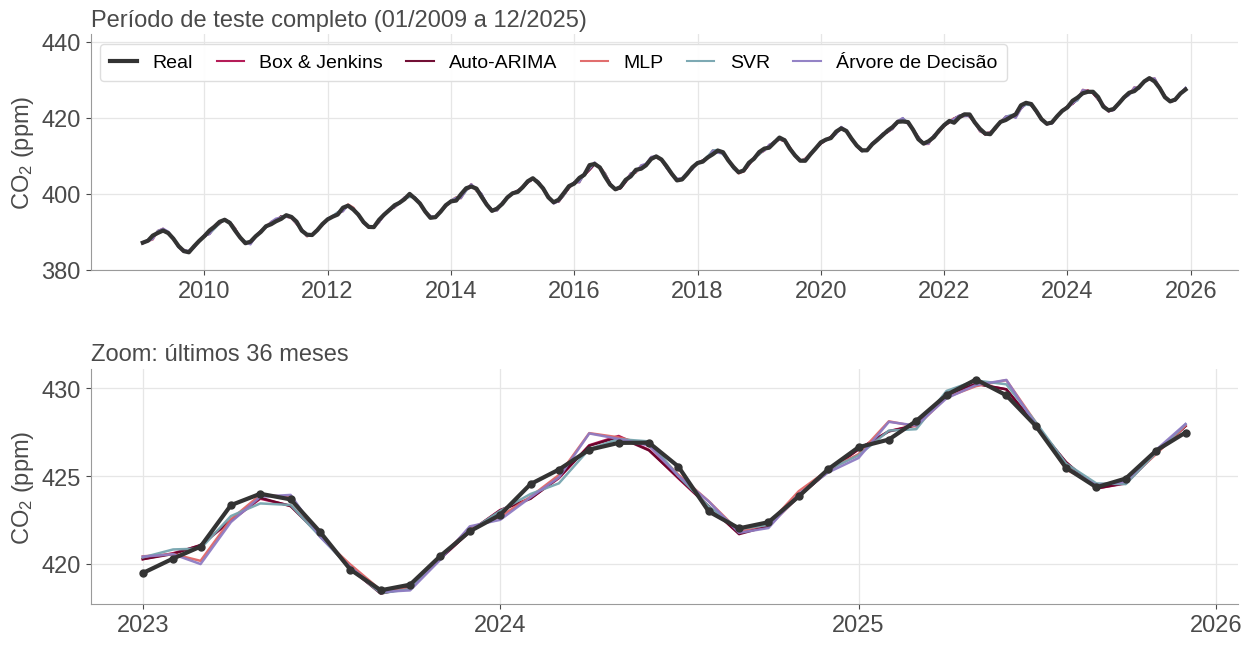

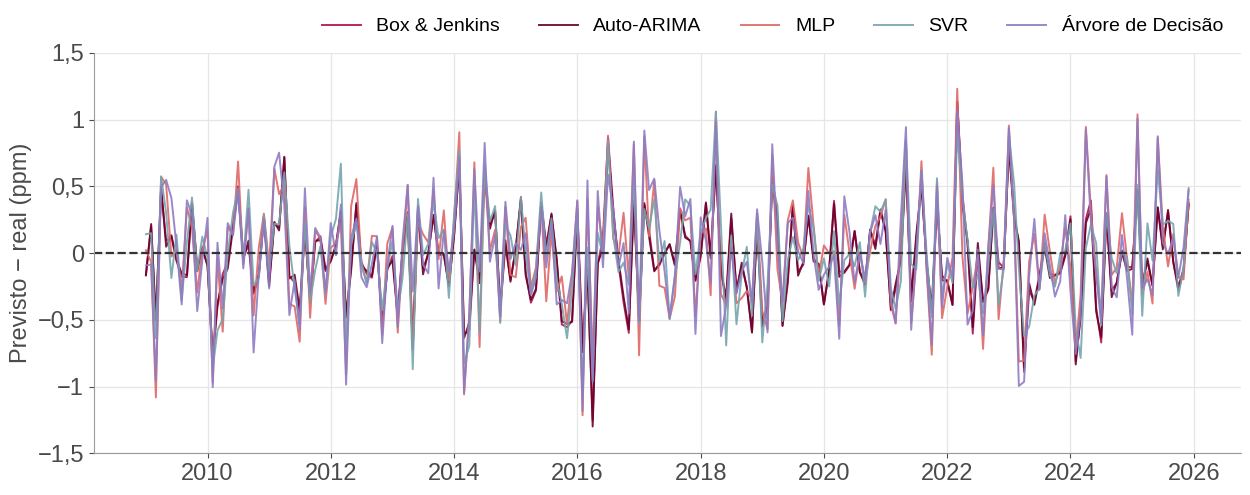

Erro absoluto máximo: 1.30 ppm | viés médio de cada modelo: de -0.04 a -0.00 ppm


In [ ]:
modelos = ['I. Box & Jenkins', 'II. Auto-ARIMA', 'III. MLP', 'IV. SVR', 'V. Árvore de Decisão']
rotulos = {'I. Box & Jenkins': 'Box & Jenkins', 'II. Auto-ARIMA': 'Auto-ARIMA', 'III. MLP': 'MLP',
           'IV. SVR': 'SVR', 'V. Árvore de Decisão': 'Árvore de Decisão'}
cores = {'I. Box & Jenkins': MAG, 'II. Auto-ARIMA': MAROON, 'III. MLP': CORAL, 'IV. SVR': TEAL, 'V. Árvore de Decisão': PURPLE}

# 1 - real x previsto, período de teste completo e zoom nos últimos 36 meses (MLP e árvore: média das 10 repetições)
fig, axes = plt.subplots(2, 1, figsize=(14.8, 7.4), gridspec_kw={'hspace': 0.42})
axes[0].plot(idx_teste, real_teste, color='#333333', lw=3.0, label='Real', zorder=5)
for nome in modelos:
    axes[0].plot(idx_teste, RESULTADOS[nome]['prev'].mean(axis=0), color=cores[nome], lw=1.5, alpha=0.95, label=rotulos[nome])
axes[0].set_title('Período de teste completo (01/2009 a 12/2025)', loc='left', fontsize=17, color=TXT)
axes[0].legend(ncol=6, fontsize=14, loc='upper left', frameon=True, framealpha=0.95, edgecolor='#DDD',
               borderpad=0.5, handlelength=1.4, columnspacing=1.2)
axes[0].set_ylim(380, 442)

ultimos = slice(-36, None)
axes[1].plot(idx_teste[ultimos], real_teste[ultimos], color='#333333', lw=3.0, marker='o', ms=5, zorder=5)
for nome in modelos:
    axes[1].plot(idx_teste[ultimos], RESULTADOS[nome]['prev'].mean(axis=0)[ultimos], color=cores[nome], lw=1.8, alpha=0.95)
axes[1].set_title('Zoom: últimos 36 meses', loc='left', fontsize=17, color=TXT)
for ax, passo in zip(axes, (2, 1)):
    ax.set_ylabel('CO$_2$ (ppm)')
    ax.xaxis.set_major_locator(mdates.YearLocator(passo))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.show()

# 2 - erro de previsão (previsto - real)
erros_teste = {nome: RESULTADOS[nome]['prev'].mean(axis=0) - real_teste for nome in modelos}
fig, ax = plt.subplots(figsize=(14.8, 5.2))
for nome in modelos:
    ax.plot(idx_teste, erros_teste[nome], color=cores[nome], lw=1.4, alpha=0.9, label=rotulos[nome])
ax.axhline(0, color='#333', ls='--', lw=1.6)
ax.set_ylabel('Previsto − real (ppm)')
ax.set_ylim(-1.5, 1.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.yaxis.set_major_formatter(FuncFormatter(br))
ax.legend(ncol=5, fontsize=14, loc='lower right', bbox_to_anchor=(1.0, 1.0), frameon=False)   # legenda acima do gráfico, sem cobrir as linhas
plt.show()

vieses = [e.mean() for e in erros_teste.values()]
print(f"Erro absoluto máximo: {max(np.abs(e).max() for e in erros_teste.values()):.2f} ppm | "
      f"viés médio de cada modelo: de {min(vieses):+.2f} a {max(vieses):+.2f} ppm")

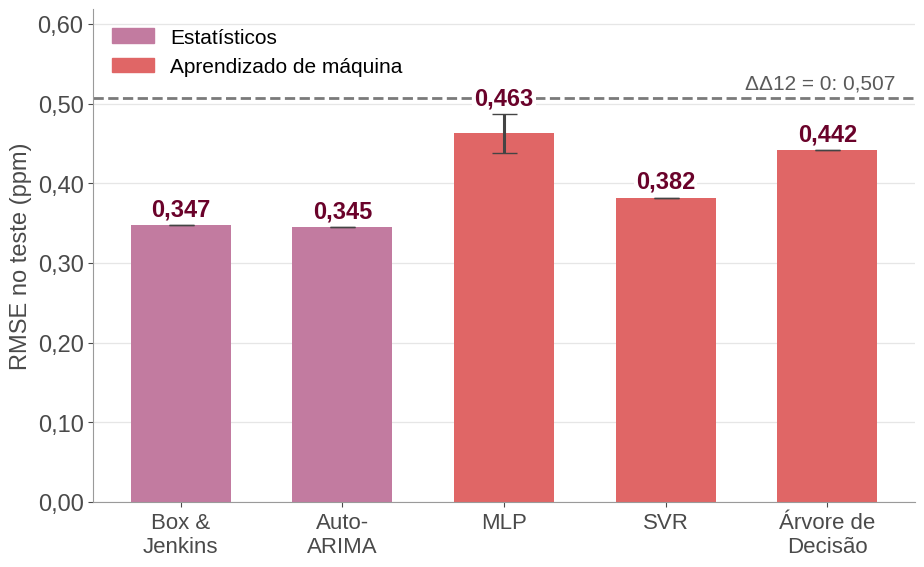

Menor RMSE no teste entre os modelos I a V: II. Auto-ARIMA


In [ ]:
# RMSE (ppm) no teste: média e desvio padrão das 10 repetições
medias = [RESULTADOS[m]['metricas']['RMSE (ppm)'].mean() for m in modelos]
desvios = [RESULTADOS[m]['metricas']['RMSE (ppm)'].std() for m in modelos]
rmse_ref = RESULTADOS['(ref.) ΔΔ12 = 0']['metricas']['RMSE (ppm)'].mean()

fig, ax = plt.subplots(figsize=(10.6, 6.4))
ax.bar(range(len(modelos)), medias, yerr=desvios, capsize=9, width=0.62, color=[MAUVE, MAUVE, CORAL, CORAL, CORAL],
       error_kw={'lw': 2.2, 'ecolor': '#444'})
ax.axhline(rmse_ref, color='#7A7A7A', ls='--', lw=2)
ax.text(len(modelos) - 0.58, rmse_ref + 0.012, f'ΔΔ12 = 0: {rmse_ref:.3f}'.replace('.', ','), ha='right', fontsize=15, color='#5A5A5A')
for i, (m_, s_) in enumerate(zip(medias, desvios)):
    ax.text(i, m_ + s_ + 0.012, f'{m_:.3f}'.replace('.', ','), ha='center', fontsize=17, fontweight='bold', color=MAROON,
            zorder=6, bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ax.set_xticks(range(len(modelos)))
ax.set_xticklabels(['Box &\nJenkins', 'Auto-\nARIMA', 'MLP', 'SVR', 'Árvore de\nDecisão'], fontsize=16)
ax.set_ylim(0, max(rmse_ref, max(m_ + s_ for m_, s_ in zip(medias, desvios))) * 1.22)
ax.set_ylabel('RMSE no teste (ppm)')
ax.yaxis.set_major_formatter(FuncFormatter(br2))
ax.grid(axis='x', visible=False)
ax.legend(handles=[Patch(color=MAUVE, label='Estatísticos'), Patch(color=CORAL, label='Aprendizado de máquina')],
          loc='upper left', fontsize=15, frameon=False)
plt.show()

melhor_nome = min(modelos, key=lambda m: RESULTADOS[m]['metricas']['RMSE'].mean())
print("Menor RMSE no teste entre os modelos I a V:", melhor_nome)

### Modelos e hiperparâmetros finais

In [ ]:
pd.DataFrame({'Modelo': list(RESULTADOS), 'Configuração final': [r['config'] for r in RESULTADOS.values()]})

,Modelo,Configuração final
0,I. Box & Jenkins,"SARIMA(0, 1, 1)(0, 1, 1, 12)"
1,II. Auto-ARIMA,"SARIMA(1, 1, 1)(1, 0, 1, 12)"
2,III. MLP,"MLP: L=12, camadas=(32, 16), alpha=0.01"
3,IV. SVR,"SVR: L=24, kernel=linear, C=1, gamma=scale, ep..."
4,V. Árvore de Decisão,"Árvore: L=12, max_depth=2, min_samples_leaf=1"
5,(ref.) Naive,y[t] = y[t-1]
6,(ref.) ΔΔ12 = 0,y[t] = y[t-1] + y[t-12] - y[t-13]





# Série: manchas solares (anual, 1700–2008)

In [ ]:
import warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
warnings.filterwarnings("ignore")

In [ ]:
d = sm.datasets.sunspots.load_pandas().data
d.index = pd.to_datetime(d["YEAR"].astype(int).astype(str), format="%Y")
SERIES = {"Manchas solares": d["SUNACTIVITY"].asfreq("YS")}

In [ ]:
display(d.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 309 entries, 1700-01-01 to 2008-01-01
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   YEAR         309 non-null    float64
 1   SUNACTIVITY  309 non-null    float64
dtypes: float64(2)
memory usage: 7.2 KB


None

In [ ]:
display(d.head(1))

,YEAR,SUNACTIVITY
YEAR,,
1700-01-01,1700.0,5.0


count    309.00
mean      49.75
std       40.45
min        0.00
25%       16.00
50%       40.00
75%       69.80
max      190.20
Name: SUNACTIVITY, dtype: float64
Variância: 1636.41
Inclinação da tendência linear: 0.1 atividade solar/ano
Série original                     ADF p = 0.0531 (NÃO estacionária) | KPSS p = 0.016 (NÃO estacionária)


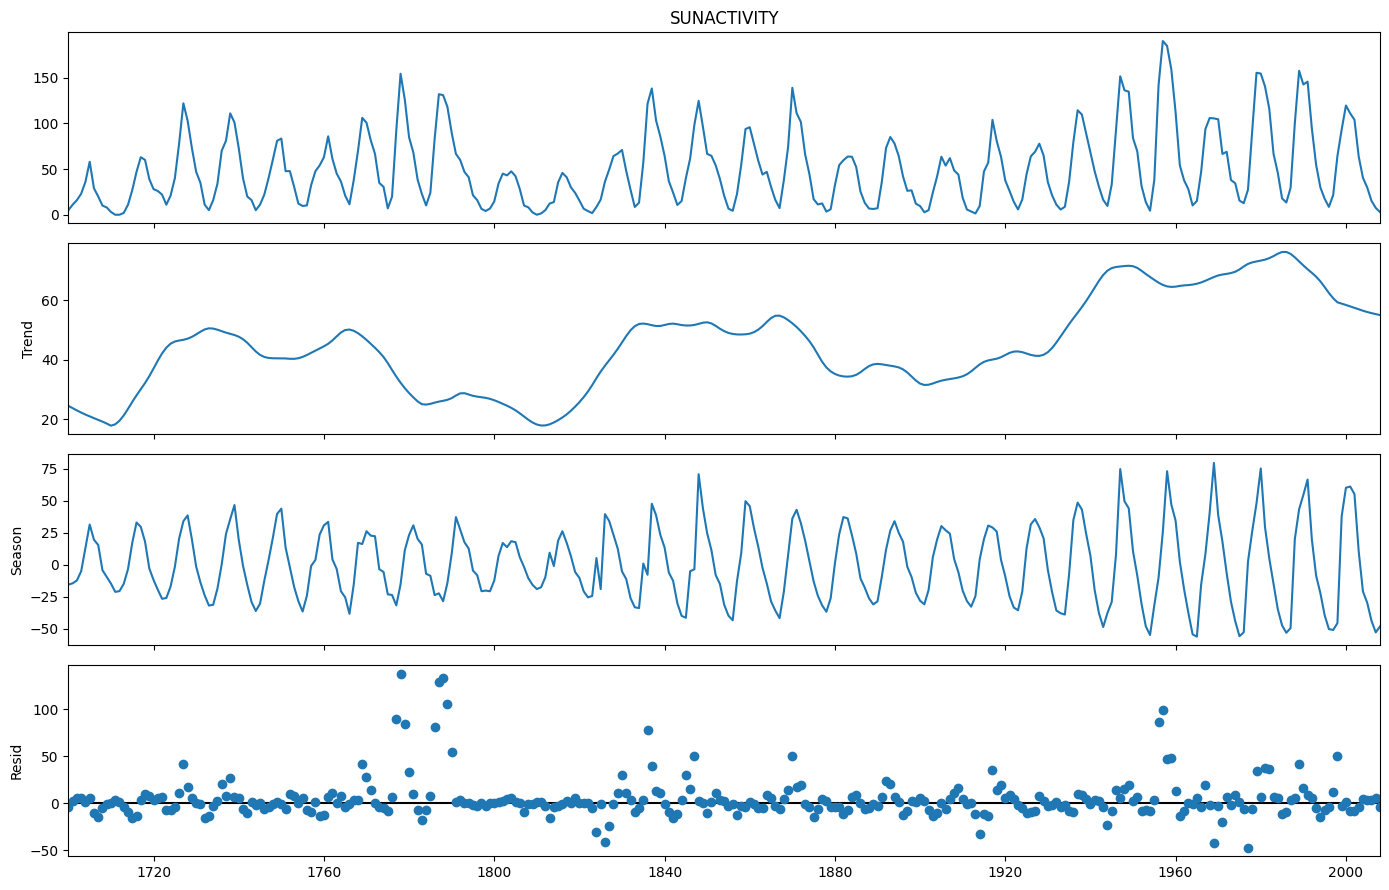

Força da sazonalidade: 0.634 | Força da tendência: 0.315
Pico sazonal: +37.99 | vale sazonal: -30.84 | amplitude: 68.83


In [ ]:
data = SERIES["Manchas solares"].dropna()

# estatísticas descritivas
print(data.describe().round(2))
print("Variância:", round(data.var(), 2))

# tendência: inclinação da reta ajustada (atividade solar por ano)
anos = np.arange(len(data))
inclinacao = np.polyfit(anos, data.values, 1)[0]

print("Inclinação da tendência linear:",
    round(inclinacao, 2),
    "atividade solar/ano")


# estacionariedade (ADF: H0 = não estacionária | KPSS: H0 = estacionária)
def testar_estacionariedade(x, nome):
    p_adf = adfuller(x, autolag="AIC")[1]
    p_kpss = kpss(x, regression="c", nlags="auto")[1]

    print(f"{nome:<34} "
        f"ADF p = {p_adf:.4f} "
        f"({'estacionária' if p_adf < 0.05 else 'NÃO estacionária'}) | "
        f"KPSS p = {p_kpss:.3f} "
        f"({'estacionária' if p_kpss >= 0.05 else 'NÃO estacionária'})")

testar_estacionariedade(data, "Série original")


#decomposição stl
stl = STL(data, period=11, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()


# força da sazonalidade e da tendência
forca_sazonal = max(0,
    1 - np.var(stl.resid) /
    np.var(stl.seasonal + stl.resid))

forca_tendencia = max(0,
    1 - np.var(stl.resid) /
    np.var(stl.trend + stl.resid))

print(f"Força da sazonalidade: {forca_sazonal:.3f} | "
    f"Força da tendência: {forca_tendencia:.3f}")

# perfil sazonal medio
perfil = stl.seasonal.groupby(stl.seasonal.index.year % 11).mean()

print( f"Pico sazonal: {perfil.max():+.2f} | "
    f"vale sazonal: {perfil.min():+.2f} | "
    f"amplitude: {(perfil.max() - perfil.min()):.2f}")

O conjunto de dados Sunspot contém 306 observações anuais sobre manchas solares. Inicialmente, foram aplicados testes à série completa para uma análise preliminar.

A série de manchas solares apresentou média de 49,75 e desvio padrão de 40,45, evidenciando elevada variabilidade ao longo do período analisado. A tendência linear apresentou inclinação de apenas 0,10 unidade de atividade solar por ano, indicando uma tendência global crescente de baixa intensidade. A decomposição STL identificou força de sazonalidade de 0,634, superior à força da tendência, de 0,315, indicando que o comportamento periódico exerce maior influência sobre a série do que a tendência de longo prazo. O componente sazonal apresentou pico de +37,99 e vale de −30,84, resultando em amplitude de 68,83 unidades. Quanto à estacionariedade, o teste ADF apresentou p-valor de 0,0531, resultado limítrofe ao nível de 5%, enquanto o KPSS apresentou p-valor de 0,016, rejeitando a hipótese de estacionariedade. Dessa forma, a série original é considerada não estacionária.


**2. Funções de apoio.**


In [ ]:
def split_temporal(s, p_tr=0.50, p_val=0.25):
    n = len(s)
    n_tr, n_val = int(n * p_tr), int(n * p_val)
    return n_tr, n_val, n - n_tr - n_val   # tamanhos de treino, validação e teste

def normalizar(s, n_tr):
    # Min-Max [0,1] ajustado SOMENTE no treino
    sc = MinMaxScaler(feature_range=(0, 1)).fit(s.values[:n_tr].reshape(-1, 1))
    z = sc.transform(s.values.reshape(-1, 1)).ravel()
    return z, sc

def metricas(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat)
    mse = np.mean((y - yhat) ** 2)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": np.mean(np.abs(y - yhat))}

def avaliar(sc, z, pred_val, pred_te, n_tr, n_val):
    # métricas na ESCALA ORIGINAL (inverse_transform)
    inv = lambda a: sc.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()
    yv, yt = inv(z[n_tr:n_tr + n_val]), inv(z[n_tr + n_val:])
    return metricas(yv, inv(pred_val)), metricas(yt, inv(pred_te))

**3. Análise exploratória e estacionariedade (apenas no treino)**

== Manchas solares: treino=154, validação=77, teste=78
count    154.000
mean      44.113
std       35.316
min        0.000
25%       14.625
50%       36.550
75%       64.575
max      154.400


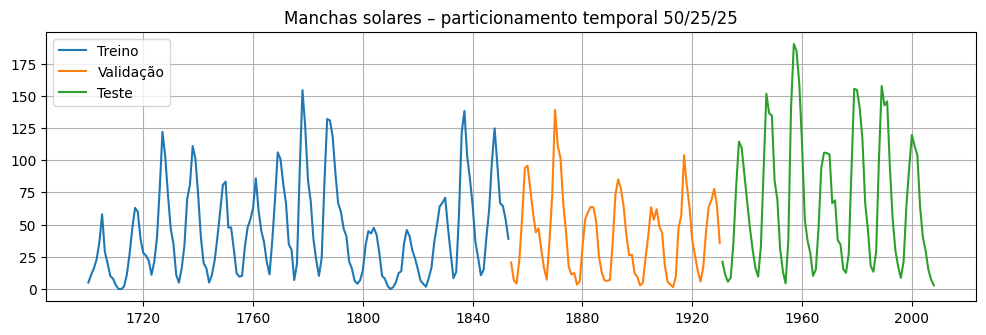

d=0: ADF p=0.1994 (H0: raiz unitária) | KPSS p=0.1000 (H0: estacionária)


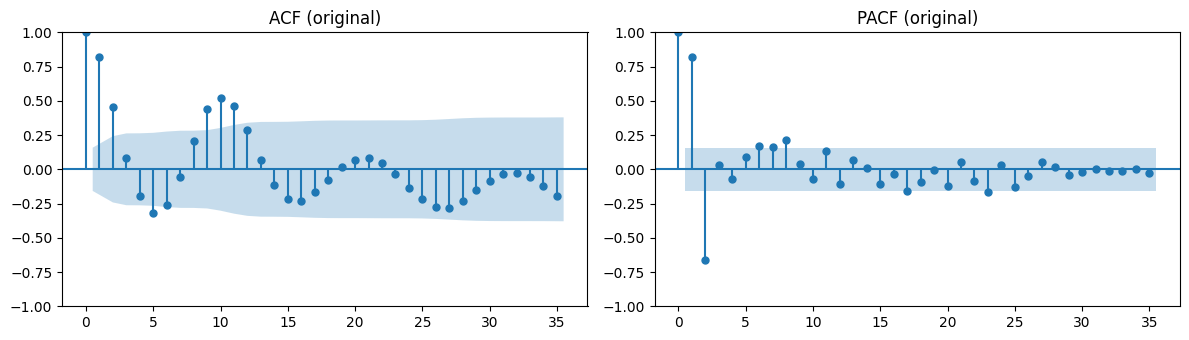

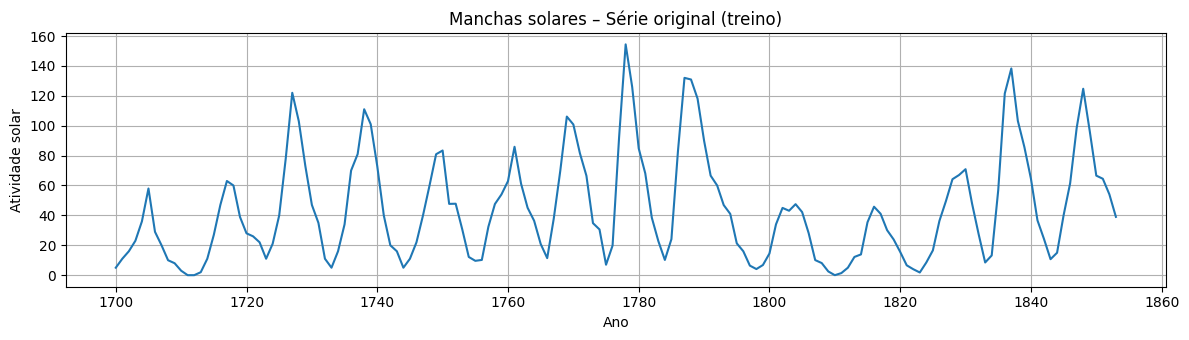

d=1: ADF p=0.0000 (H0: raiz unitária) | KPSS p=0.1000 (H0: estacionária)


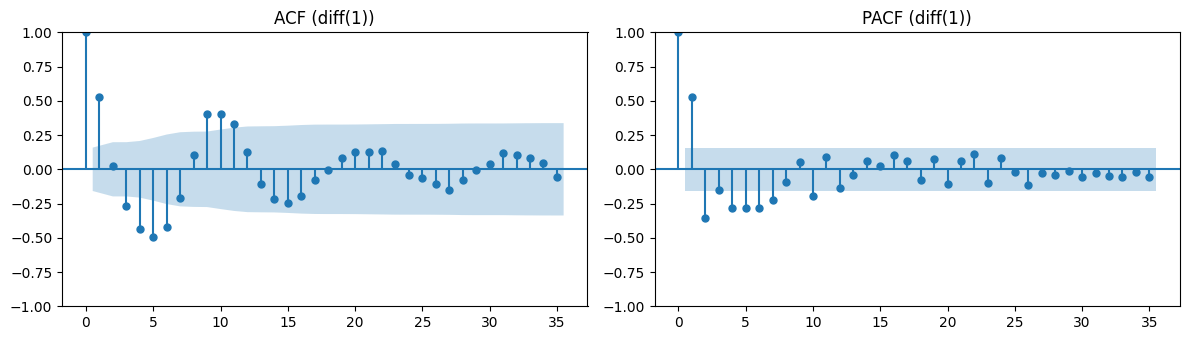

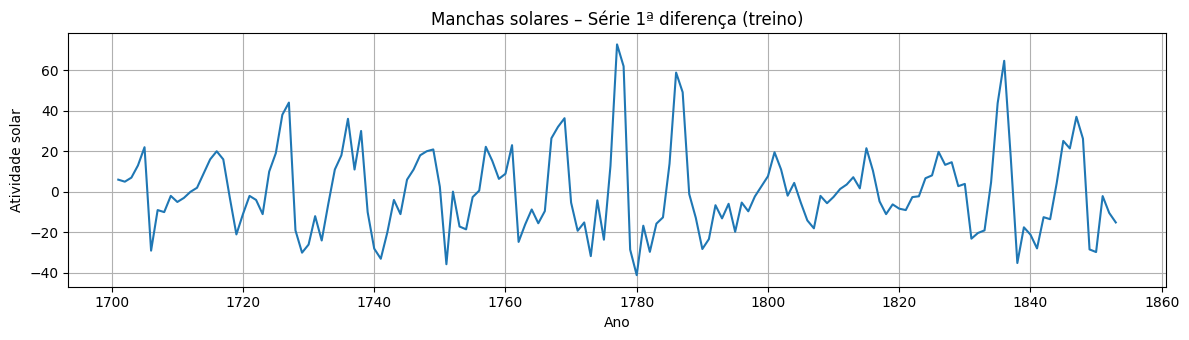

In [ ]:
def analise(nome, s):
    n_tr, n_val, n_te = split_temporal(s)
    tr = s.iloc[:n_tr]
    print(f"== {nome}: treino={n_tr}, validação={n_val}, teste={n_te}")
    print(tr.describe().round(3).to_string())

    fig, ax = plt.subplots(1, 1, figsize=(12, 3.5))
    ax.plot(s.index[:n_tr], s.values[:n_tr], label="Treino")
    ax.plot(s.index[n_tr:n_tr+n_val], s.values[n_tr:n_tr+n_val], label="Validação")
    ax.plot(s.index[n_tr+n_val:], s.values[n_tr+n_val:], label="Teste")
    ax.set_title(f"{nome} – particionamento temporal 50/25/25"); ax.legend(); ax.grid(True)
    plt.show()

    for d in (0, 1):
        x = tr.diff(1).dropna() if d else tr
        adf_p = adfuller(x)[1]
        kpss_p = kpss(x, regression="c", nlags="auto")[1]
        #funções + valores dos dois testes
        print(f"d={d}: ADF p={adf_p:.4f} (H0: raiz unitária) | KPSS p={kpss_p:.4f} (H0: estacionária)")
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        plot_acf(x, ax=axes[0], lags=35); plot_pacf(x, ax=axes[1], lags=35, method="ywm")
        rot = "original" if d == 0 else "diff(1)"
        axes[0].set_title(f"ACF ({rot})"); axes[1].set_title(f"PACF ({rot})")
        plt.tight_layout(); plt.show()
        #grafico (treino) antes e depois de diferenciar
        fig, ax = plt.subplots(figsize=(12, 3.5))
        ax.plot(x.index, x.values)
        rot = "original (treino)" if d == 0 else "1ª diferença (treino)"
        ax.set_title(f"{nome} – Série {rot}")
        ax.set_xlabel("Ano")
        ax.set_ylabel("Atividade solar")
        ax.grid(True)
        plt.tight_layout()
        plt.show()

for nome, s in SERIES.items():
    analise(nome, s)

Na série original (d=0), o teste ADF apresentou p-valor de 0,1994, não permitindo rejeitar a hipótese nula de presença de raiz unitária. O teste KPSS apresentou p-valor de 0,1000, não rejeitando a hipótese nula de estacionariedade. Dessa forma, os testes apresentam resultados inconclusivos para a série original. Após a diferenciação de primeira ordem (d=1), o ADF apresentou p-valor de 0,0000, rejeitando a hipótese de raiz unitária, enquanto o KPSS apresentou p-valor de 0,1000, não rejeitando a hipótese de estacionariedade. Assim, os dois testes fornecem evidências mais consistentes de estacionariedade após uma diferenciação, indicando d=1 como uma escolha adequada.

**4. Modelos estatísticos**


***(i) Box & Jenkins (ARIMA manual)***

O parâmetro d foi fixado em 1, pois a primeira diferenciação tornou a série estacionária. Em seguida, foram testadas diferentes combinações de p e q, indicadas pela ACF/PACF, buscando encontrar o modelo com melhor desempenho preditivo e resíduos adequados.

Manchas solares
    ordem    AIC    BIC  Ljung-Box p (11)  Ljung-Box p (21)
(1, 1, 0) -223.2 -217.1             0.000             0.000
(2, 1, 0) -241.7 -232.6             0.000             0.000
(3, 1, 0) -243.2 -231.1             0.000             0.000
(0, 1, 1) -232.8 -226.7             0.000             0.000
(0, 1, 2) -236.0 -226.9             0.000             0.000
(1, 1, 1) -234.9 -225.8             0.000             0.000
(2, 1, 1) -276.0 -263.9             0.034             0.246
(2, 1, 2) -276.0 -260.9             0.019             0.209
(3, 1, 1) -274.3 -259.2             0.033             0.254
(3, 1, 2) -272.2 -254.0             0.066             0.375

Ordem escolhida: (2, 1, 2)

Ljung-Box do modelo escolhido:
      lb_stat  lb_pvalue
11  22.835798   0.018641
21  25.935132   0.208933


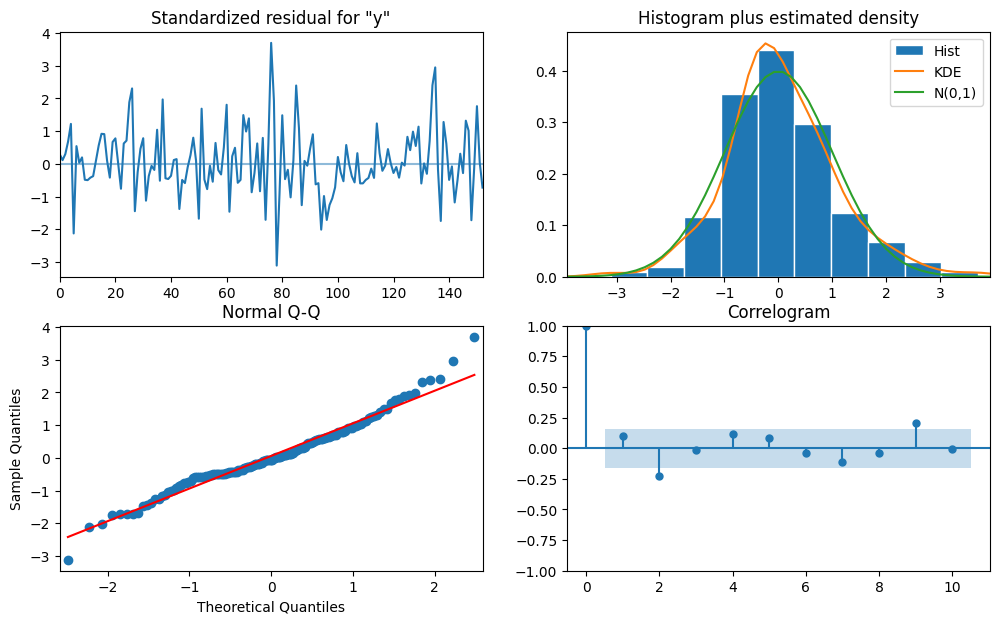


RMSE (teste): 0.1098
MAE  (teste): 0.0844


In [ ]:
def arima_um_passo(z, order, n_tr):
    #ajusta o modelo somente no treino
    res = ARIMA(z[:n_tr], order=order).fit()
    # Mantém os parâmetros fixos e usa as observações reais
    full = res.apply(z)
    # Previsão de 1 passo à frente nos 50% finais
    pred = full.predict( start=n_tr,end=len(z) - 1)
    return res, pred


CANDIDATAS_BJ = {"Manchas solares": [
    (1, 1, 0),
    (2, 1, 0),
    (3, 1, 0),
    (0, 1, 1),
    (0, 1, 2),
    (1, 1, 1),
    (2, 1, 1),
    (2, 1, 2),
    (3, 1, 1),
    (3, 1, 2),
]}


def box_jenkins(nome, s):
    n_tr, n_val, n_te = split_temporal(s)
    # normalização usando somente o treino
    z, sc = normalizar(s, n_tr)

    linhas = []
    for order in CANDIDATAS_BJ[nome]:
        # ajuste no treino + previsão 1 passo à frente
        res, pred = arima_um_passo(z, order, n_tr)

        # Ljung-Box dos resíduos
        lb = acorr_ljungbox(
            res.resid,
            lags=[11, 21],
            return_df=True
        )

        linhas.append({
            "ordem": order,
            "AIC": res.aic,
            "BIC": res.bic,
            "Ljung-Box p (11)": lb.loc[11, "lb_pvalue"],
            "Ljung-Box p (21)": lb.loc[21, "lb_pvalue"]
        })

    # tabela dos modelos candidatos
    tab = pd.DataFrame(linhas)

    print(nome)
    print(
        tab.round({
            "AIC": 1,
            "BIC": 1,
            "Ljung-Box p (11)": 3,
            "Ljung-Box p (21)": 3
        }).to_string(index=False)
    )

    # escolha pelo menor AIC
    best = tab.loc[tab["AIC"].idxmin(), "ordem"]

    print("\nOrdem escolhida:", best)

    # ajusta novamente o modelo escolhido
    res, pred = arima_um_passo(z, best, n_tr)

    # diagnóstico dos resíduos
    print("\nLjung-Box do modelo escolhido:")
    print(
        acorr_ljungbox(
            res.resid,
            lags=[11, 21],
            return_df=True
        )
    )

    # diagnóstico gráfico
    res.plot_diagnostics(figsize=(12, 7))
    plt.show()
    y_true = z[n_tr:]

    rmse = np.sqrt(np.mean((y_true - pred) ** 2))
    mae = np.mean(np.abs(y_true - pred))

    print(f"\nRMSE (teste): {rmse:.4f}")
    print(f"MAE  (teste): {mae:.4f}")

    return best, rmse, mae, pred


BJ = { nome: box_jenkins(nome, s) for nome, s in SERIES.items() if nome in CANDIDATAS_BJ}

O modelo ARIMA(2,1,2) foi selecionado por apresentar o menor AIC (-276,0), indicando o melhor equilíbrio entre qualidade do ajuste e complexidade entre os modelos avaliados. O BIC do modelo foi -260,9, enquanto o menor BIC foi obtido pelo ARIMA(2,1,1) (-263,9).

Na análise dos resíduos, o teste de Ljung-Box apresentou p=0,0186 no lag 11, indicando autocorrelação significativa nos resíduos, e p=0,2089 no lag 21, não indicando autocorrelação significativa nesse lag. Portanto, o modelo ainda não captura completamente toda a estrutura temporal da série, especialmente a associada ao ciclo aproximado de 11 anos das manchas solares.

***(ii) Auto-ARIMA***

In [ ]:
def rodar_auto(nome, s):
    n_tr, n_val, n_te = split_temporal(s)
    z, sc = normalizar(s, n_tr)

    # escolhe a ordem usando apenas o treino
    modelo_auto = auto_arima(
        z[:n_tr],
        start_p=0,
        start_q=0,
        max_p=5,
        max_q=5,
        d=1,
        seasonal=False,
        information_criterion="aic",
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore"
    )

    order = modelo_auto.order

    #ajusta novamente a ordem escolhida no statsmodels
    #usando somente os 50% de treino
    res = ARIMA(z[:n_tr], order=order).fit()

    # um passo a frente
    full = res.apply(z)
    pred = full.predict(
        start=n_tr,
        end=len(z) - 1
    )

    # avaliação nos 50% finais
    y_true = z[n_tr:]

    rmse = np.sqrt(np.mean((y_true - pred) ** 2))
    mae = np.mean(np.abs(y_true - pred))

    # ljjung-Box
    lb = acorr_ljungbox(
        res.resid,
        lags=[11, 21],
        return_df=True
    )

    print(f"{nome}: Auto-ARIMA = {order}")
    print(f"AIC = {res.aic:.2f}")
    print(f"BIC = {res.bic:.2f}")
    print(f"Ljung-Box p (11) = {lb.loc[11, 'lb_pvalue']:.3f}")
    print(f"Ljung-Box p (21) = {lb.loc[21, 'lb_pvalue']:.3f}")
    print(f"RMSE (teste) = {rmse:.4f}")
    print(f"MAE  (teste) = {mae:.4f}")

    return order, res, rmse, mae, pred


AUTO = {nome: rodar_auto(nome, s) for nome, s in SERIES.items()}

Manchas solares: Auto-ARIMA = (2, 1, 3)
AIC = -286.10
BIC = -267.92
Ljung-Box p (11) = 0.369
Ljung-Box p (21) = 0.779
RMSE (teste) = 0.1146
MAE  (teste) = 0.0873


O Auto-ARIMA selecionou automaticamente o modelo ARIMA(2,1,3), utilizando o AIC como critério de seleção. O modelo apresentou AIC de -286,10 e BIC de -267,92. Na análise dos resíduos, os testes de Ljung-Box apresentaram p-valores de 0,369 no lag 11 e 0,779 no lag 21, ambos superiores a 0,05, indicando ausência de autocorrelação significativa nos resíduos. Na avaliação dos 50% finais da série, utilizando previsões um passo à frente, o modelo apresentou RMSE = 0,1146 e MAE = 0,0873. Comparado ao ARIMA(2,1,2) selecionado manualmente, o Auto-ARIMA apresentou melhor ajuste segundo o AIC e resíduos mais adequados, enquanto o modelo manual apresentou erros preditivos ligeiramente menores.

**5. Aprendizado de máquina.**

* Transformação supervisionada: são utilizadas janelas deslizantes, nas quais os últimos n_lags valores são usados para prever o próximo valor (one-step-ahead).

* Divisão dos dados: 50% para treino, 25% para validação e 25% para teste, mantendo a ordem temporal. As janelas podem utilizar valores do período anterior, mas o alvo pertence ao seu respectivo conjunto.

* Seleção: n_lags e hiperparâmetros são escolhidos pelo menor MSE na validação. O teste é usado apenas na avaliação final.

* Repetições: cada configuração selecionada é executada 10 vezes para calcular média e desvio padrão das métricas.

In [ ]:
def janelas(z, n_lags):
    X = np.array([z[i:i + n_lags] for i in range(len(z) - n_lags)])
    y = z[n_lags:]
    alvo_idx = np.arange(n_lags, len(z))
    return X, y, alvo_idx

MODELOS = {
    "MLP": (lambda seed, **k: MLPRegressor(
            max_iter=2000,
            early_stopping=False,
            random_state=seed,
            **k),
        [dict(hidden_layer_sizes=h, alpha=a)
            for h in [(16,), (32,), (32,16)]
            for a in [1e-4, 1e-2]]),

    "SVR": (lambda seed, **k: SVR(**k),[
            dict(C=C, gamma=g, epsilon=0.01)
            for C in [1, 10, 100]
            for g in ["scale", 0.01, 0.1]]),

    "Árvore de Decisão": (lambda seed, **k: DecisionTreeRegressor
     (random_state=seed,**k),[dict(max_depth=d, min_samples_leaf=leaf)
            for d in [3, 5, 10, None]
            for leaf in [1, 3, 5]])}

LAGS = [3, 6, 11, 15]
N_REP = 10

def rodar_ml(nome, s, nome_modelo):
    fabrica, grade = MODELOS[nome_modelo]
    n_tr, n_val, n_te = split_temporal(s)
    #normalização usando somente o treino
    z, sc = normalizar(s, n_tr)
    # seleção de lags e hiperparametros na validação
    melhor = (np.inf, None, None)

    for L in LAGS:
        X, y, t = janelas(z, L)
        m_tr = t < n_tr
        m_val = (t >= n_tr) & (t < n_tr + n_val)

        for hp in grade:

            mdl = fabrica(0, **hp)

            mdl.fit(
                X[m_tr],
                y[m_tr]
            )

            pv = mdl.predict(X[m_val])

            mse = np.mean(
                (pv - y[m_val]) ** 2
            )

            if mse < melhor[0]:
                melhor = (mse, L, hp)

    _, L, hp = melhor

    # preparação dados
    X, y, t = janelas(z, L)
    m_tr = t < n_tr

    m_val = (
        (t >= n_tr) &
        (t < n_tr + n_val)
    )

    m_te = t >= n_tr + n_val

    mets_v = []
    mets_t = []
    preds = []

    # repetições
    for seed in range(N_REP):
        mdl = fabrica(seed,**hp)
        mdl.fit( X[m_tr],y[m_tr])
        #previsões
        pv = mdl.predict(X[m_val])
        pt = mdl.predict(X[m_te])
        #métricas
        a, b = avaliar(
            sc,
            z,
            pv,
            pt,
            n_tr,
            n_val
        )

        mets_v.append(a)
        mets_t.append(b)

        #previsões na escala original
        preds.append(sc.inverse_transform(
                pt.reshape(-1, 1)
            ).ravel() )

    print(f"{nome} | {nome_modelo}: "
        f"n_lags={L}, "
        f"hiperparâmetros={hp}")

    return (L,
        hp,
        mets_v,
        mets_t,
        np.mean(preds, axis=0))

ML = {(nome, modelo): rodar_ml(nome,s,modelo)
    for nome, s in SERIES.items()
    for modelo in MODELOS}

Manchas solares | MLP: n_lags=6, hiperparâmetros={'hidden_layer_sizes': (32, 16), 'alpha': 0.0001}
Manchas solares | SVR: n_lags=3, hiperparâmetros={'C': 1, 'gamma': 'scale', 'epsilon': 0.01}
Manchas solares | Árvore de Decisão: n_lags=15, hiperparâmetros={'max_depth': 10, 'min_samples_leaf': 1}


**6. Comparação média x desvio padrão.**

          Série                  Modelo       RMSE val        MAE val     RMSE teste      MAE teste
Manchas solares Box & Jenkins (2, 1, 2)   16.956 ± 0.0   13.035 ± 0.0   16.956 ± 0.0   13.035 ± 0.0
Manchas solares    Auto-ARIMA (2, 1, 3)     17.7 ± 0.0   13.475 ± 0.0     17.7 ± 0.0   13.475 ± 0.0
Manchas solares                     MLP 18.592 ± 4.042 14.843 ± 3.603 30.571 ± 6.611 22.965 ± 6.574
Manchas solares                     SVR   12.901 ± 0.0    9.849 ± 0.0   25.802 ± 0.0   17.751 ± 0.0
Manchas solares       Árvore de Decisão 14.986 ± 0.555 10.994 ± 0.313 31.864 ± 0.358  23.74 ± 0.289


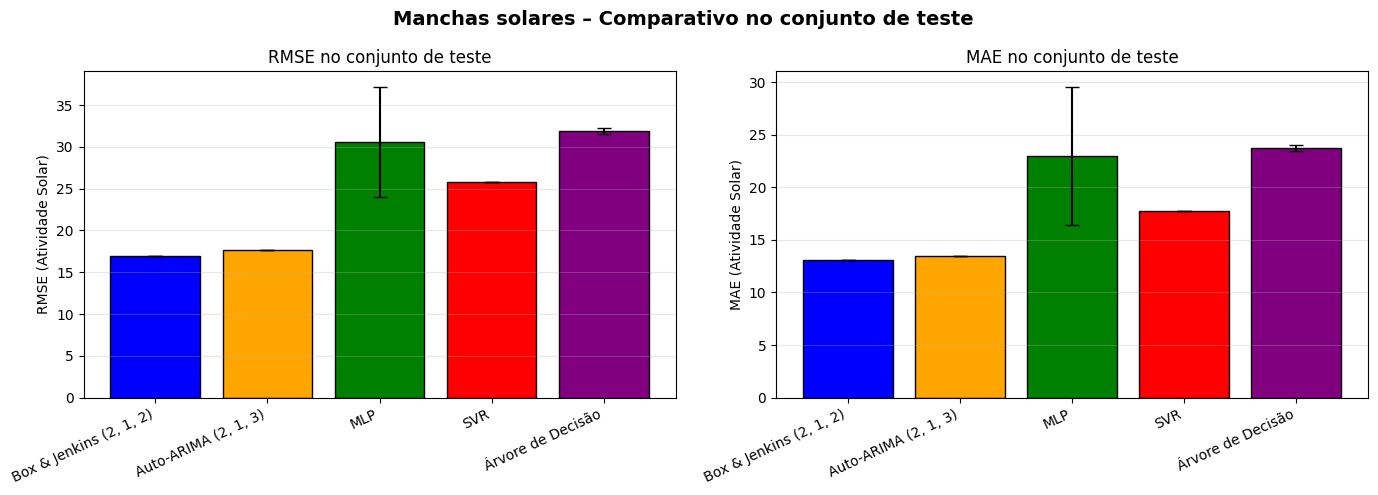

In [ ]:
def agg(lista, chave):
    valores = np.array([d[chave] for d in lista])
    return valores.mean(), valores.std()

linhas = []

for nome, s in SERIES.items():
    #escala para os modelos estatísticos
    n_tr, _, _ = split_temporal(s)
    _, sc = normalizar(s, n_tr)
    escala = sc.data_max_[0] - sc.data_min_[0]

    # Box & Jenkins
    if nome in BJ:
        ordem, rmse, mae = BJ[nome][0:3]
        linhas.append((nome,
            f"Box & Jenkins {ordem}",
            [{"RMSE": rmse * escala, "MAE": mae * escala}],
            [{"RMSE": rmse * escala, "MAE": mae * escala}]))

    # Auto-ARIMA
    ordem, res, rmse, mae, _ = AUTO[nome]
    linhas.append((nome,f"Auto-ARIMA {ordem}",
        [{"RMSE": rmse * escala, "MAE": mae * escala}],
        [{"RMSE": rmse * escala, "MAE": mae * escala}]))

    # Machine Learning
    for modelo in MODELOS:
        L, hp, mv, mt, _ = ML[(nome, modelo)]
        linhas.append((nome, modelo, mv, mt))


#medio e desvio

resultados = []
for nome, modelo, validacao, teste in linhas:
    rmse_val, dp_rmse_val = agg(validacao, "RMSE")
    mae_val, dp_mae_val = agg(validacao, "MAE")

    rmse_teste, dp_rmse_teste = agg(teste, "RMSE")
    mae_teste, dp_mae_teste = agg(teste, "MAE")

    resultados.append({
        "Série": nome,
        "Modelo": modelo,
        "RMSE val": rmse_val,
        "DP RMSE val": dp_rmse_val,
        "MAE val": mae_val,
        "DP MAE val": dp_mae_val,
        "RMSE teste": rmse_teste,
        "DP RMSE teste": dp_rmse_teste,
        "MAE teste": mae_teste,
        "DP MAE teste": dp_mae_teste
    })


tabela = pd.DataFrame(resultados)
tabela_formatada = tabela.copy()

for metrica in ["RMSE", "MAE"]:
    for conjunto in ["val", "teste"]:
        media = tabela[f"{metrica} {conjunto}"]
        dp = tabela[f"DP {metrica} {conjunto}"]

        tabela_formatada[f"{metrica} {conjunto}"] = (
            media.round(3).astype(str) + " ± " + dp.round(3).astype(str))

print(tabela_formatada[["Série", "Modelo",
         "RMSE val", "MAE val",
         "RMSE teste", "MAE teste"]].to_string(index=False))

#grafico

dados = tabela[tabela["Série"] == "Manchas solares"]
modelos = dados["Modelo"].tolist()
cores = {"Box & Jenkins": "blue",
    "Auto-ARIMA": "orange",
    "MLP": "green",
    "SVR": "red",
    "Árvore de Decisão": "purple"}

cores_modelos = [next(c for nome, c in cores.items() if modelo.startswith(nome))
    for modelo in modelos]
x = np.arange(len(modelos))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE
axes[0].bar(
    x,
    dados["RMSE teste"],
    yerr=dados["DP RMSE teste"],
    capsize=5,
    color=cores_modelos,
    edgecolor="black"
)

axes[0].set_title("RMSE no conjunto de teste")
axes[0].set_ylabel("RMSE (Atividade Solar)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(modelos, rotation=25, ha="right")
axes[0].grid(axis="y", alpha=0.3)


# MAE
axes[1].bar(
    x,
    dados["MAE teste"],
    yerr=dados["DP MAE teste"],
    capsize=5,
    color=cores_modelos,
    edgecolor="black"
)

axes[1].set_title("MAE no conjunto de teste")
axes[1].set_ylabel("MAE (Atividade Solar)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(modelos, rotation=25, ha="right")
axes[1].grid(axis="y", alpha=0.3)


fig.suptitle(
    "Manchas solares – Comparativo no conjunto de teste",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**7. Grafico Real x Previsto.**

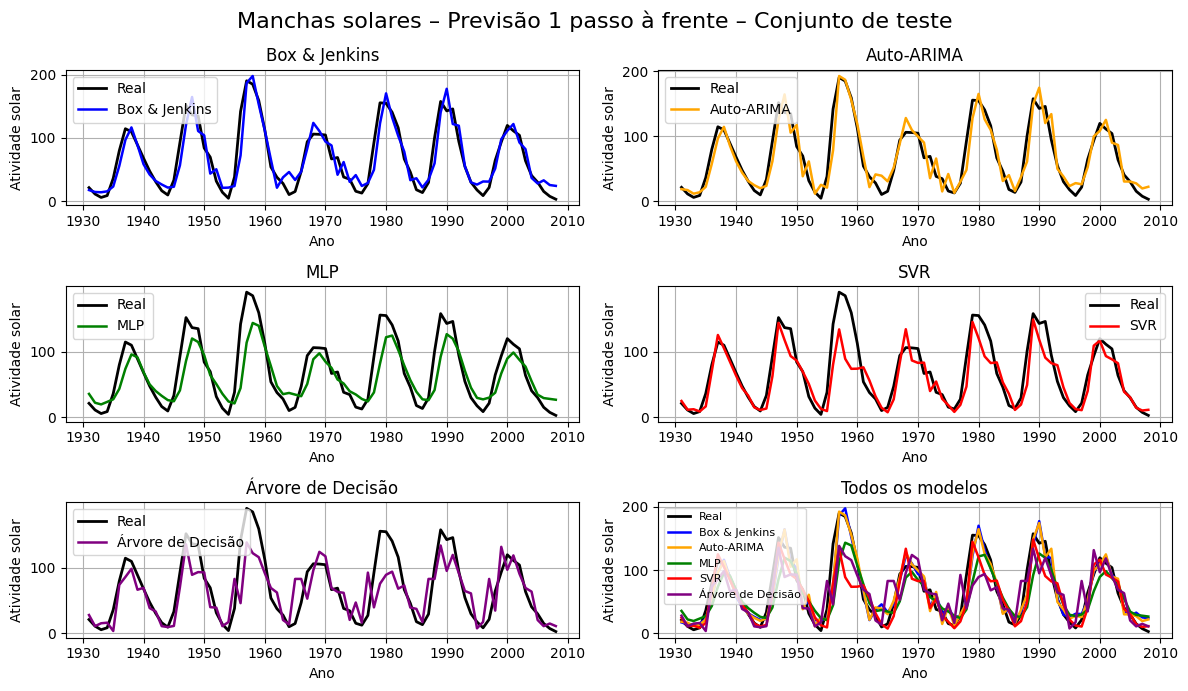

In [ ]:
for nome, s in SERIES.items():
    n_tr, n_val, n_te = split_temporal(s)
    real = s.values[n_tr + n_val:]
    idx = s.index[n_tr + n_val:]

    _, sc = normalizar(s, n_tr)
    inv = lambda x: sc.inverse_transform(
        np.asarray(x).reshape(-1, 1)
    ).ravel()

    cores = { "Box & Jenkins": "blue",
        "Auto-ARIMA": "orange",
        "MLP": "green",
        "SVR": "red",
        "Árvore de Decisão": "purple"}

    #previsões
    previsoes = {"Box & Jenkins": inv(BJ[nome][3][-n_te:]),
        "Auto-ARIMA": inv(AUTO[nome][4][-n_te:]),
        "MLP": ML[(nome, "MLP")][4],
        "SVR": ML[(nome, "SVR")][4],
        "Árvore de Decisão": ML[(nome, "Árvore de Decisão")][4]}

    #gráficos
    fig, axes = plt.subplots(3, 2, figsize=(12, 7))
    modelos = list(previsoes.keys())

    # 5 gráficos individuais
    for ax, modelo in zip(axes.flat, modelos):
        ax.plot(idx, real, color="black", lw=2, label="Real")
        ax.plot(
            idx,
            previsoes[modelo],
            color=cores[modelo],
            lw=1.8,
            label=modelo
        )

        ax.set_title(modelo)
        ax.set_xlabel("Ano")
        ax.set_ylabel("Atividade solar")
        ax.legend()
        ax.grid(True)

    #ultimo gráfico: todos
    ax = axes[2, 1]
    ax.plot(
        idx, real,
        color="black",
        lw=2,
        label="Real"
    )

    for modelo in modelos:
        ax.plot(idx,
            previsoes[modelo],
            color=cores[modelo],
            lw=1.8,
            label=modelo)

    ax.set_title("Todos os modelos")
    ax.set_xlabel("Ano")
    ax.set_ylabel("Atividade solar")
    ax.legend(fontsize=8)
    ax.grid(True)

    fig.suptitle(
        f"{nome} – Previsão 1 passo à frente – Conjunto de teste",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

**7.1** Configurações e Hiperparametros finais.


Abaixo estão detalhados os melhores hiperparâmetros, ordens e janelas temporais (`n_lags`) selecionados para todos os modelos analíticos e de Aprendizado de Máquina no conjunto de manchas solares:

| Categoria | Modelo | Configuração Final / Hiperparâmetros Ótimos |
| :--- | :--- | :--- |
| **Estatístico (Manual)** | **Box & Jenkins** | Ordem ARIMA `(2, 1, 2)` (selecionado via menor AIC) |
| **Estatístico (Automático)** | **Auto-ARIMA** | Ordem ARIMA `(2, 1, 3)` (selecionado via busca em grade stepwise pmdarima) |
| **Aprendizado de Máquina** | **MLP (Rede Neural)** | `n_lags=6`, `hidden_layer_sizes=(32, 16)`, `alpha=0.0001` (Regularização $L_2$) |
| **Aprendizado de Máquina** | **SVR (Suporte Vetorial)** | `n_lags=3`, `C=1`, `gamma='scale'`, `epsilon=0.01` |
| **Aprendizado de Máquina** | **Árvore de Decisão** | `n_lags=15`, `max_depth=10`, `min_samples_leaf=1` |